In [5]:
%pip install opencv-python numpy pyautogui mss matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 6.6 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.3 MB 8.8 MB/s eta 0:00:01
   ----------------------- ---------------- 5.5/9.3 MB 9.9 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.3 MB 10.8 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 10.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------------------- -- 2.4/2.5 MB 11.8 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 11.2 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- --------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [4]:
import cv2
import numpy as np
import pyautogui as pyg
import mss
import matplotlib.pyplot as plt
import time

pyg.PAUSE = 0.05
pyg.FAILSAFE = True

print("Gem Bot 初始化完成！")

Gem Bot 初始化完成！


C:\Users\曾薏帆\AppData\Local\Temp\ipykernel_29032\4202567482.py:3: DeprecationWarning: mss.mss is deprecated and will be removed in a future release; use mss.MSS instead
  with mss.mss() as sct:


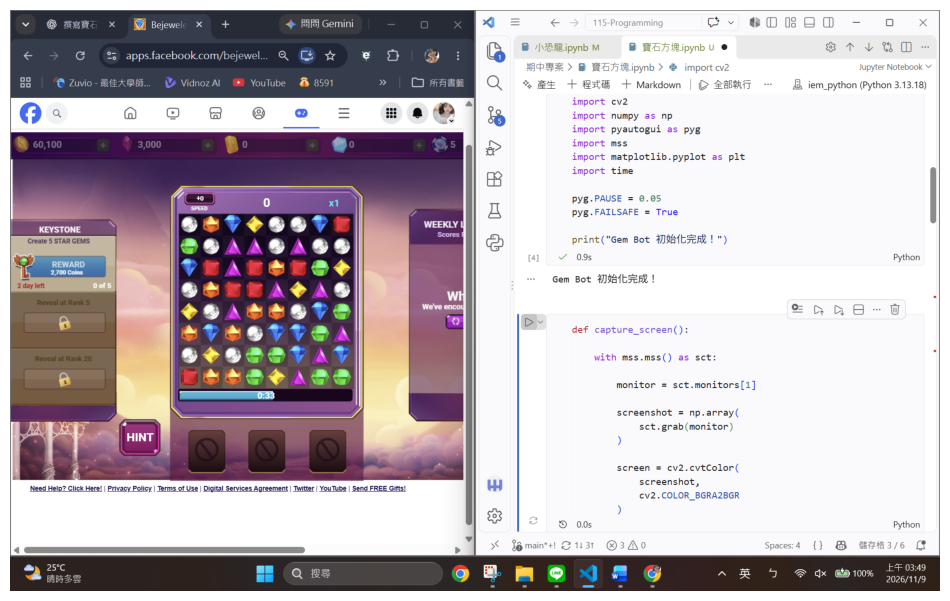

In [5]:
def capture_screen():

    with mss.mss() as sct:

        monitor = sct.monitors[1]

        screenshot = np.array(
            sct.grab(monitor)
        )

        screen = cv2.cvtColor(
            screenshot,
            cv2.COLOR_BGRA2BGR
        )

    return screen


# 擷取畫面
screen = capture_screen()

# 顯示畫面
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(screen, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

螢幕尺寸： (1200, 1920, 3)


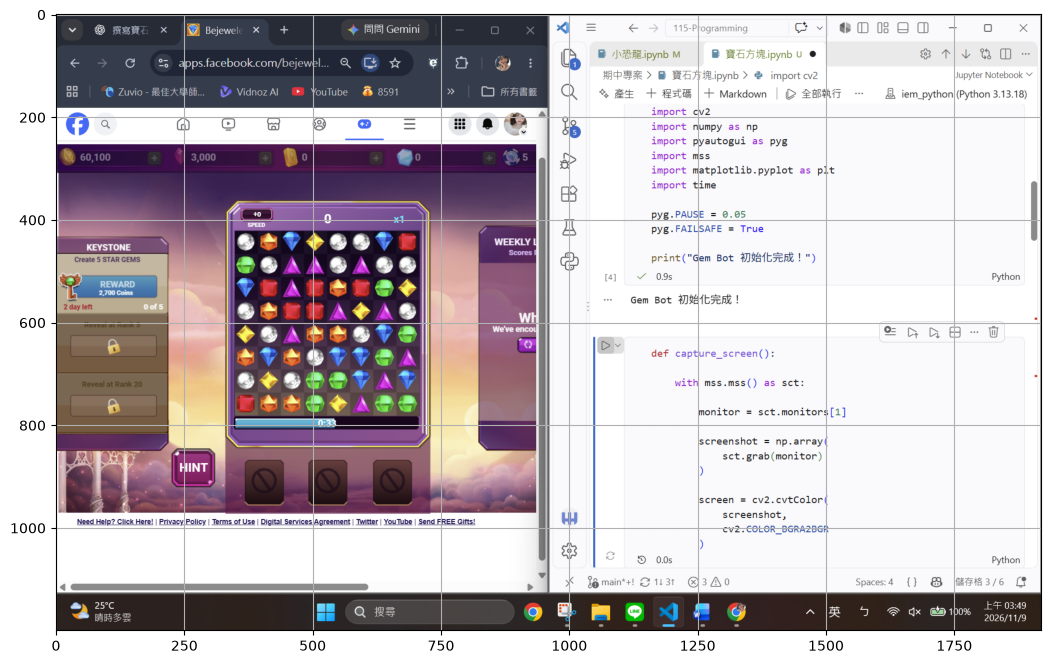

In [6]:
# 查看螢幕解析度
print("螢幕尺寸：", screen.shape)

# 顯示完整截圖與座標
plt.figure(figsize=(14, 8))

plt.imshow(
    cv2.cvtColor(screen, cv2.COLOR_BGR2RGB)
)

plt.axis("on")
plt.grid()

plt.show()

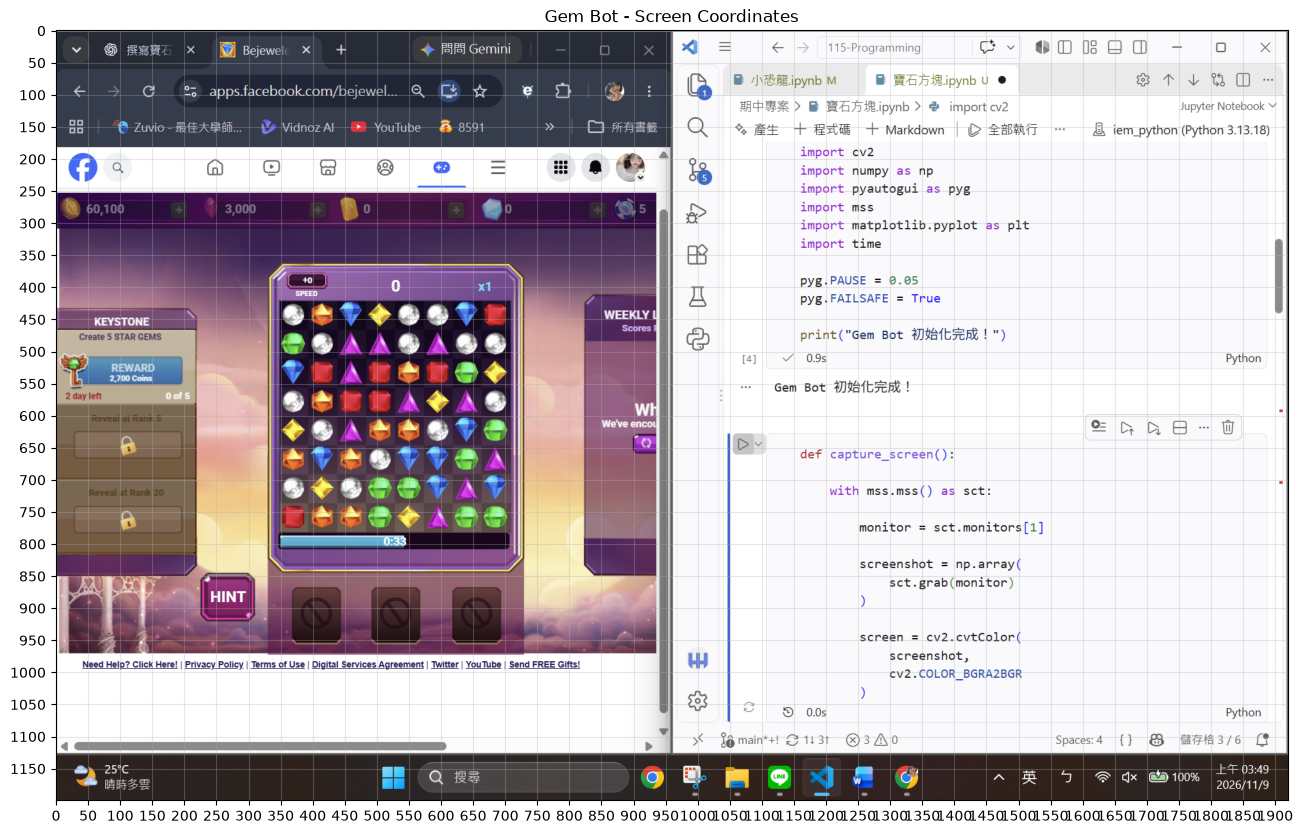

In [7]:
# 顯示螢幕與座標
fig, ax = plt.subplots(figsize=(16, 10))

ax.imshow(
    cv2.cvtColor(screen, cv2.COLOR_BGR2RGB)
)

ax.set_xticks(np.arange(0, 1920, 50))
ax.set_yticks(np.arange(0, 1200, 50))

ax.grid(True, alpha=0.3)

ax.set_title("Gem Bot - Screen Coordinates")

plt.show()

請框選完整的 8x8 寶石棋盤
========== 棋盤座標 ==========
左上角 X: 350
左上角 Y: 421
棋盤寬度: 361
棋盤高度: 363


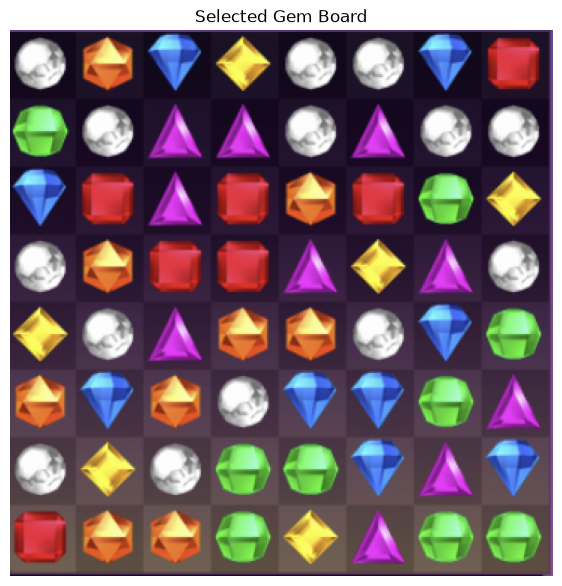

In [8]:
# ==============================
# 棋盤區域定位
# ==============================

print("請框選完整的 8x8 寶石棋盤")

# 開啟選取視窗
x, y, w, h = cv2.selectROI(
    "Select Gem Board",
    screen,
    fromCenter=False,
    showCrosshair=True
)

cv2.destroyAllWindows()

# 儲存棋盤座標
board_x = int(x)
board_y = int(y)
board_w = int(w)
board_h = int(h)

print("========== 棋盤座標 ==========")
print("左上角 X:", board_x)
print("左上角 Y:", board_y)
print("棋盤寬度:", board_w)
print("棋盤高度:", board_h)

# 擷取棋盤
board_image = screen[
    board_y:board_y + board_h,
    board_x:board_x + board_w
]

# 顯示棋盤
plt.figure(figsize=(7, 9))

plt.imshow(
    cv2.cvtColor(board_image, cv2.COLOR_BGR2RGB)
)

plt.title("Selected Gem Board")
plt.axis("off")
plt.show()

In [11]:
# ==============================
# Cell 6：寶石顏色辨識
# ==============================

def detect_gem_color(patch):

    # BGR 轉 HSV
    hsv = cv2.cvtColor(
        patch,
        cv2.COLOR_BGR2HSV
    )

    # 取中央區域的 HSV 中位數
    pixels = hsv.reshape(-1, 3)

    h, s, v = np.median(pixels, axis=0)

    # 白色寶石
    if s < 55 and v > 100:
        return "W"

    # 紅色寶石
    if h < 8 or h >= 170:
        return "R"

    # 橘色寶石
    elif 8 <= h < 20:
        return "O"

    # 黃色寶石
    elif 20 <= h < 36:
        return "Y"

    # 綠色寶石
    elif 36 <= h < 85:
        return "G"

    # 藍色寶石
    elif 85 <= h < 125:
        return "B"

    # 紫色寶石
    elif 125 <= h < 170:
        return "P"

    return "?"


# ==============================
# Cell 7：建立 8x8 棋盤矩陣
# ==============================

rows = 8
cols = 8

cell_w = board_w / cols
cell_h = board_h / rows

board = []

for r in range(rows):

    row = []

    for c in range(cols):

        # 計算每格中心
        cx = int((c + 0.5) * cell_w)
        cy = int((r + 0.5) * cell_h)

        # 擷取中央 40% 區域
        patch_w = int(cell_w * 0.4)
        patch_h = int(cell_h * 0.4)

        patch = board_image[
            cy - patch_h // 2 : cy + patch_h // 2,
            cx - patch_w // 2 : cx + patch_w // 2
        ]

        color = detect_gem_color(patch)

        row.append(color)

    board.append(row)


# ==============================
# 顯示辨識結果
# ==============================

print("========== Gem Board ==========")

for row in board:
    print(" ".join(row))

print("\n棋盤尺寸：", len(board), "x", len(board[0]))

print("\n寶石種類統計：")

unique, counts = np.unique(
    np.array(board),
    return_counts=True
)

for color, count in zip(unique, counts):
    print(f"{color}: {count}")

========== Gem Board ==========
W O B Y W W B R
G W P P W P W W
B R P R O R G Y
W O R R P Y P W
Y W P O O W B G
O B O W B B G P
W Y W G G B P B
R O O G Y P G G

棋盤尺寸： 8 x 8

寶石種類統計：
B: 9
G: 9
O: 9
P: 10
R: 7
W: 14
Y: 6


        GEM BOT - MOVE ANALYSIS

第 1 名
交換位置：(1, 4) → (1, 5)
預計消除：6 顆

第 2 名
交換位置：(0, 5) → (1, 5)
預計消除：4 顆

第 3 名
交換位置：(0, 6) → (1, 6)
預計消除：3 顆

第 4 名
交換位置：(2, 1) → (3, 1)
預計消除：3 顆

第 5 名
交換位置：(2, 2) → (3, 2)
預計消除：3 顆


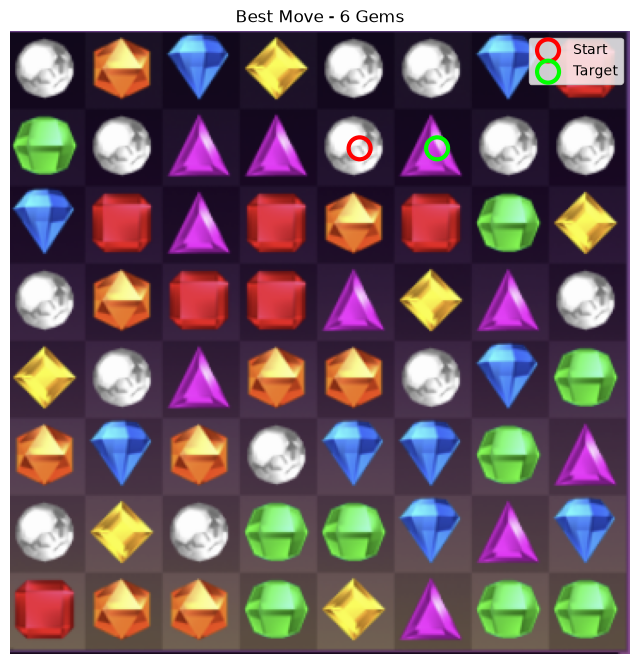


分析完成！


In [13]:

# ==========================================
# Gem Bot - Move Solver
# 最佳寶石交換與消除演算法
# ==========================================

def find_matches(board):

    rows, cols = board.shape
    matched = set()

    # 橫向檢查
    for r in range(rows):
        c = 0

        while c < cols:
            start = c
            color = board[r, c]

            while c < cols and board[r, c] == color:
                c += 1

            if c - start >= 3:
                for j in range(start, c):
                    matched.add((r, j))

    # 直向檢查
    for c in range(cols):
        r = 0

        while r < rows:
            start = r
            color = board[r, c]

            while r < rows and board[r, c] == color:
                r += 1

            if r - start >= 3:
                for j in range(start, r):
                    matched.add((j, c))

    return matched


# ==========================================
# 尋找最佳交換位置
# ==========================================

def find_best_moves(board):

    board = np.array(board)
    rows, cols = board.shape

    results = []

    for r in range(rows):
        for c in range(cols):

            neighbors = []

            if c + 1 < cols:
                neighbors.append((r, c + 1))

            if r + 1 < rows:
                neighbors.append((r + 1, c))

            for nr, nc in neighbors:

                new_board = board.copy()

                # 交換寶石
                new_board[r, c], new_board[nr, nc] = (
                    new_board[nr, nc],
                    new_board[r, c]
                )

                matches = find_matches(new_board)

                # 排除無效移動
                if not matches:
                    continue

                # 必須有交換的寶石參與消除
                if (r, c) not in matches and (nr, nc) not in matches:
                    continue

                results.append({
                    "from": (r, c),
                    "to": (nr, nc),
                    "score": len(matches),
                    "matches": matches
                })

    results.sort(
        key=lambda x: x["score"],
        reverse=True
    )

    return results


# ==========================================
# 執行最佳移動分析
# ==========================================

best_moves = find_best_moves(board)

print("=" * 45)
print("        GEM BOT - MOVE ANALYSIS")
print("=" * 45)

if best_moves:

    for i, move in enumerate(best_moves[:5]):

        print(f"\n第 {i+1} 名")
        print(f"交換位置：{move['from']} → {move['to']}")
        print(f"預計消除：{move['score']} 顆")

    # ======================================
    # 最佳移動視覺化
    # ======================================

    best = best_moves[0]

    r1, c1 = best["from"]
    r2, c2 = best["to"]

    plt.figure(figsize=(8, 9))

    plt.imshow(
        cv2.cvtColor(board_image, cv2.COLOR_BGR2RGB)
    )

    # 起點：紅色
    plt.scatter(
        (c1 + 0.5) * cell_w,
        (r1 + 0.5) * cell_h,
        s=250,
        facecolors="none",
        edgecolors="red",
        linewidths=3,
        label="Start"
    )

    # 終點：綠色
    plt.scatter(
        (c2 + 0.5) * cell_w,
        (r2 + 0.5) * cell_h,
        s=250,
        facecolors="none",
        edgecolors="lime",
        linewidths=3,
        label="Target"
    )

    plt.title(
        f"Best Move - {best['score']} Gems"
    )

    plt.legend()
    plt.axis("off")
    plt.show()

else:
    print("目前沒有找到有效的消除移動。")

print("\n分析完成！")


In [14]:
# ==========================================
# Gem Bot - Mouse Position Calibration
# ==========================================

# 取得目前最佳移動
best = best_moves[0]

r1, c1 = best["from"]
r2, c2 = best["to"]

# 計算螢幕座標
start_x = int(board_x + (c1 + 0.5) * cell_w)
start_y = int(board_y + (r1 + 0.5) * cell_h)

end_x = int(board_x + (c2 + 0.5) * cell_w)
end_y = int(board_y + (r2 + 0.5) * cell_h)

print("========== Mouse Calibration ==========")

print("起點座標：", start_x, start_y)
print("終點座標：", end_x, end_y)

# 只移動滑鼠，不點擊、不拖曳
pyg.moveTo(
    start_x,
    start_y,
    duration=0.5
)

print("滑鼠已移動至第一顆寶石中心！")

========== Mouse Calibration ==========
起點座標： 553 489
終點座標： 598 489
滑鼠已移動至第一顆寶石中心！


========== AUTO PLAY ==========
最佳移動： (1, 4) → (1, 5)
預計消除： 6 顆
已完成寶石交換！


C:\Users\曾薏帆\AppData\Local\Temp\ipykernel_29032\4202567482.py:3: DeprecationWarning: mss.mss is deprecated and will be removed in a future release; use mss.MSS instead
  with mss.mss() as sct:



========== NEW BOARD ==========
P P P P P P P P
P P P P P P P P
O P W G P G P O
B B P O P Y W P
P W O P W B P P
G P P Y G B Y W
Y O Y Y Y P G G
O P G P W O B P

辨識格數： 64
未知格數： 0


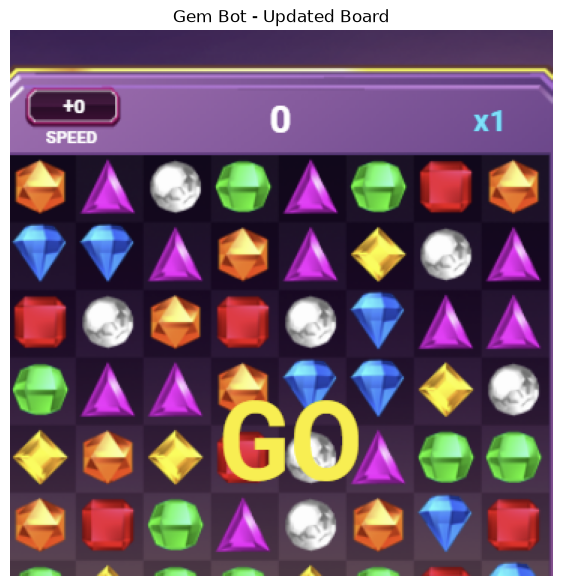


========== NEXT MOVE ==========
第 1 名：(4, 0) → (5, 0) | 消除 26 顆
第 2 名：(4, 2) → (4, 3) | 消除 26 顆
第 3 名：(4, 3) → (5, 3) | 消除 26 顆
第 4 名：(1, 7) → (2, 7) | 消除 25 顆
第 5 名：(2, 6) → (2, 7) | 消除 25 顆


In [15]:

# ==========================================
# Gem Bot - Auto Play One Move
# 自動交換一次並重新辨識棋盤
# ==========================================

# 1. 確認是否有有效移動

if not best_moves:
    print("目前沒有可執行的移動！")

else:

    # 取得最佳移動
    best = best_moves[0]

    r1, c1 = best["from"]
    r2, c2 = best["to"]

    # 計算螢幕座標
    start_x = int(board_x + (c1 + 0.5) * cell_w)
    start_y = int(board_y + (r1 + 0.5) * cell_h)

    end_x = int(board_x + (c2 + 0.5) * cell_w)
    end_y = int(board_y + (r2 + 0.5) * cell_h)

    print("========== AUTO PLAY ==========")
    print("最佳移動：", best["from"], "→", best["to"])
    print("預計消除：", best["score"], "顆")

    # 2. 自動拖曳寶石

    pyg.moveTo(start_x, start_y, duration=0.2)

    pyg.mouseDown()

    try:
        pyg.moveTo(
            end_x,
            end_y,
            duration=0.3
        )
    finally:
        pyg.mouseUp()

    print("已完成寶石交換！")

    # 3. 等待消除及掉落動畫

    time.sleep(1.5)

    # 4. 重新擷取遊戲畫面

    screen_after = capture_screen()

    board_image_after = screen_after[
        board_y:board_y + board_h,
        board_x:board_x + board_w
    ]

    # 5. 重新辨識 8x8 棋盤

    new_board = []

    for r in range(8):

        row = []

        for c in range(8):

            cx = int((c + 0.5) * cell_w)
            cy = int((r + 0.5) * cell_h)

            patch_w = int(cell_w * 0.4)
            patch_h = int(cell_h * 0.4)

            patch = board_image_after[
                cy - patch_h // 2:cy + patch_h // 2,
                cx - patch_w // 2:cx + patch_w // 2
            ]

            color = detect_gem_color(patch)

            row.append(color)

        new_board.append(row)

    # 更新目前棋盤
    board = np.array(new_board)

    # 6. 顯示新棋盤

    print("\n========== NEW BOARD ==========")

    for row in board:
        print(" ".join(row))

    print("\n辨識格數：", board.size)
    print("未知格數：", np.sum(board == "?"))

    # 7. 顯示重新擷取的棋盤

    plt.figure(figsize=(7, 8))

    plt.imshow(
        cv2.cvtColor(
            board_image_after,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title("Gem Bot - Updated Board")
    plt.axis("off")
    plt.show()

    # 8. 計算下一次最佳移動

    best_moves = find_best_moves(board)

    print("\n========== NEXT MOVE ==========")

    if best_moves:

        for i, move in enumerate(best_moves[:5]):

            print(
                f"第 {i+1} 名："
                f"{move['from']} → {move['to']} "
                f"| 消除 {move['score']} 顆"
            )

    else:
        print("目前沒有有效移動。")


In [3]:

# ==========================================
# Gem Bot - Recalibrate Screen
# 重新校正棋盤座標
# ==========================================

# 1. 重新擷取目前螢幕
screen = capture_screen()

print("目前螢幕尺寸：", screen.shape)

# 2. 重新框選棋盤
print("請重新框選完整的 8x8 棋盤")

x, y, w, h = cv2.selectROI(
    "Recalibrate Gem Board",
    screen,
    fromCenter=False,
    showCrosshair=True
)

cv2.destroyAllWindows()

if w == 0 or h == 0:
    raise ValueError("沒有選取棋盤，請重新執行！")

# 3. 更新棋盤座標
board_x = int(x)
board_y = int(y)
board_w = int(w)
board_h = int(h)

# 4. 重新計算每格大小
cell_w = board_w / 8
cell_h = board_h / 8

# 5. 更新棋盤圖片
board_image = screen[
    board_y:board_y + board_h,
    board_x:board_x + board_w
]

print("\n========== 新座標 ==========")
print("X:", board_x)
print("Y:", board_y)
print("Width:", board_w)
print("Height:", board_h)
print("Cell Width:", cell_w)
print("Cell Height:", cell_h)

# 6. 顯示重新定位結果
plt.figure(figsize=(7, 8))

plt.imshow(
    cv2.cvtColor(board_image, cv2.COLOR_BGR2RGB)
)

plt.title("Recalibrated Gem Board")
plt.axis("off")
plt.show()


NameError: name 'capture_screen' is not defined

In [4]:

# ==========================================
# Gem Bot - Recalibrate Screen
# 重新校正棋盤座標
# ==========================================

# 1. 重新擷取目前螢幕
screen = capture_screen()

print("目前螢幕尺寸：", screen.shape)

# 2. 重新框選棋盤
print("請重新框選完整的 8x8 棋盤")

x, y, w, h = cv2.selectROI(
    "Recalibrate Gem Board",
    screen,
    fromCenter=False,
    showCrosshair=True
)

cv2.destroyAllWindows()

if w == 0 or h == 0:
    raise ValueError("沒有選取棋盤，請重新執行！")

# 3. 更新棋盤座標
board_x = int(x)
board_y = int(y)
board_w = int(w)
board_h = int(h)

# 4. 重新計算每格大小
cell_w = board_w / 8
cell_h = board_h / 8

# 5. 更新棋盤圖片
board_image = screen[
    board_y:board_y + board_h,
    board_x:board_x + board_w
]

print("\n========== 新座標 ==========")
print("X:", board_x)
print("Y:", board_y)
print("Width:", board_w)
print("Height:", board_h)
print("Cell Width:", cell_w)
print("Cell Height:", cell_h)

# 6. 顯示重新定位結果
plt.figure(figsize=(7, 8))

plt.imshow(
    cv2.cvtColor(board_image, cv2.COLOR_BGR2RGB)
)

plt.title("Recalibrated Gem Board")
plt.axis("off")
plt.show()


NameError: name 'capture_screen' is not defined

In [5]:
# ==========================================
# Gem Bot - Screen Capture
# ==========================================

def capture_screen():

    with mss.MSS() as sct:

        monitor = sct.monitors[1]

        screenshot = np.array(
            sct.grab(monitor)
        )

        screen = cv2.cvtColor(
            screenshot,
            cv2.COLOR_BGRA2BGR
        )

    return screen


# 測試
screen = capture_screen()

print("螢幕擷取成功！")
print("螢幕尺寸：", screen.shape)

NameError: name 'mss' is not defined

In [6]:
# ==========================================
# Gem Bot - Import Libraries
# ==========================================

import cv2
import numpy as np
import pyautogui as pyg
import mss
import matplotlib.pyplot as plt
import time

pyg.PAUSE = 0.05
pyg.FAILSAFE = True

print("Gem Bot 套件載入完成！")

Gem Bot 套件載入完成！


In [7]:
# ==========================================
# Gem Bot - Screen Capture
# ==========================================

def capture_screen():

    with mss.MSS() as sct:

        monitor = sct.monitors[1]

        screenshot = np.array(
            sct.grab(monitor)
        )

        screen = cv2.cvtColor(
            screenshot,
            cv2.COLOR_BGRA2BGR
        )

    return screen


screen = capture_screen()

print("螢幕擷取成功！")
print("螢幕尺寸：", screen.shape)

螢幕擷取成功！
螢幕尺寸： (1200, 1920, 3)


請框選完整的 8x8 寶石棋盤

========== 新棋盤座標 ==========
X: 417
Y: 569
Width: 435
Height: 435
Cell Width: 54.375
Cell Height: 54.375


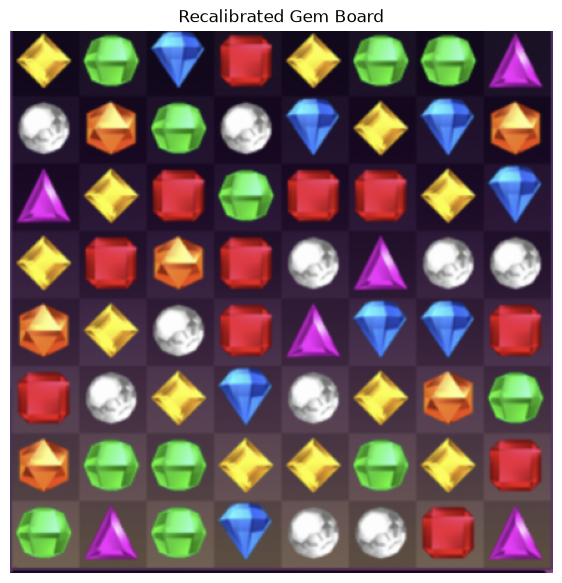

In [8]:
# ==========================================
# Gem Bot - Recalibrate Screen
# ==========================================

screen = capture_screen()

print("請框選完整的 8x8 寶石棋盤")

x, y, w, h = cv2.selectROI(
    "Recalibrate Gem Board",
    screen,
    fromCenter=False,
    showCrosshair=True
)

cv2.destroyAllWindows()

if w == 0 or h == 0:
    raise ValueError("棋盤框選失敗，請重新執行")

# 更新座標
board_x = int(x)
board_y = int(y)
board_w = int(w)
board_h = int(h)

# 計算格子尺寸
cell_w = board_w / 8
cell_h = board_h / 8

# 擷取棋盤
board_image = screen[
    board_y:board_y + board_h,
    board_x:board_x + board_w
]

print("\n========== 新棋盤座標 ==========")
print("X:", board_x)
print("Y:", board_y)
print("Width:", board_w)
print("Height:", board_h)
print("Cell Width:", cell_w)
print("Cell Height:", cell_h)

# 顯示結果
plt.figure(figsize=(7, 8))
plt.imshow(cv2.cvtColor(board_image, cv2.COLOR_BGR2RGB))
plt.title("Recalibrated Gem Board")
plt.axis("off")
plt.show()

========== NEW BOARD ==========
Y W Y G O R G R
B Y G O B O W P
R G W W P W O Y
Y Y B Y Y W G P
O P R W B B O B
W O Y Y R R G G
W P G B W P G B
O B R B R Y W O
棋盤尺寸： (8, 8)
未知格數： 0

========== BEST MOVES ==========
1. (0, 1) -> (1, 1) | 消除 3 顆
2. (0, 4) -> (1, 4) | 消除 3 顆
3. (1, 5) -> (1, 6) | 消除 3 顆
4. (2, 4) -> (2, 5) | 消除 3 顆
5. (3, 1) -> (3, 2) | 消除 3 顆

========== MOUSE POSITION ==========
起點： 498 596
終點： 498 650
滑鼠定位完成，尚未執行交換。


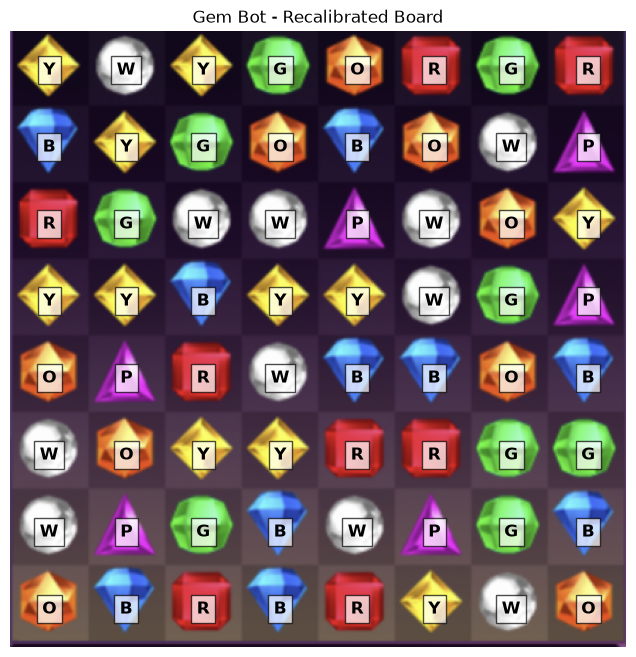

In [11]:

# ==========================================
# GEM BOT - Rebuild & Recalibrate
# 重新辨識棋盤、計算最佳移動、測試滑鼠
# ==========================================

# 1. 寶石顏色辨識

def detect_gem_color(patch):

    hsv = cv2.cvtColor(patch, cv2.COLOR_BGR2HSV)

    h, s, v = np.median(
        hsv.reshape(-1, 3), axis=0
    )

    if s < 55 and v > 100:
        return "W"
    elif h < 8 or h >= 170:
        return "R"
    elif h < 20:
        return "O"
    elif h < 36:
        return "Y"
    elif h < 85:
        return "G"
    elif h < 125:
        return "B"
    elif h < 170:
        return "P"

    return "?"


# 2. 重新擷取目前棋盤

screen = capture_screen()

board_image = screen[
    board_y:board_y + board_h,
    board_x:board_x + board_w
]

cell_w = board_w / 8
cell_h = board_h / 8

# 3. 建立 8x8 棋盤矩陣

board = []

for r in range(8):

    row = []

    for c in range(8):

        cx = int((c + 0.5) * cell_w)
        cy = int((r + 0.5) * cell_h)

        pw = int(cell_w * 0.4)
        ph = int(cell_h * 0.4)

        patch = board_image[
            cy-ph//2:cy+ph//2,
            cx-pw//2:cx+pw//2
        ]

        row.append(detect_gem_color(patch))

    board.append(row)

board = np.array(board)

print("========== NEW BOARD ==========")

for row in board:
    print(" ".join(row))

print("棋盤尺寸：", board.shape)
print("未知格數：", np.sum(board == "?"))


# 4. 消除判斷

def find_matches(board):

    rows, cols = board.shape
    matched = set()

    for r in range(rows):

        c = 0

        while c < cols:

            start = c
            color = board[r, c]

            while c < cols and board[r, c] == color:
                c += 1

            if c-start >= 3:
                for j in range(start, c):
                    matched.add((r, j))

    for c in range(cols):

        r = 0

        while r < rows:

            start = r
            color = board[r, c]

            while r < rows and board[r, c] == color:
                r += 1

            if r-start >= 3:
                for j in range(start, r):
                    matched.add((j, c))

    return matched


# 5. 最佳交換計算

def find_best_moves(board):

    results = []
    rows, cols = board.shape

    if np.any(board == "?"):
        raise ValueError("棋盤存在未知寶石，暫停策略計算")

    for r in range(rows):
        for c in range(cols):

            neighbors = []

            if c+1 < cols:
                neighbors.append((r, c+1))

            if r+1 < rows:
                neighbors.append((r+1, c))

            for nr, nc in neighbors:

                new_board = board.copy()

                new_board[r,c], new_board[nr,nc] = (
                    new_board[nr,nc],
                    new_board[r,c]
                )

                matches = find_matches(new_board)

                if not matches:
                    continue

                if (r,c) not in matches and (nr,nc) not in matches:
                    continue

                results.append({
                    "from": (r,c),
                    "to": (nr,nc),
                    "score": len(matches),
                    "matches": matches
                })

    return sorted(
        results,
        key=lambda x: x["score"],
        reverse=True
    )


# 6. 計算最佳移動

best_moves = find_best_moves(board)

print("\n========== BEST MOVES ==========")

if not best_moves:
    print("目前沒有有效移動")

else:

    for i, move in enumerate(best_moves[:5]):

        print(
            f"{i+1}. {move['from']} -> {move['to']} "
            f"| 消除 {move['score']} 顆"
        )

    # 7. 計算滑鼠座標

    best = best_moves[0]

    r1, c1 = best["from"]
    r2, c2 = best["to"]

    start_x = int(board_x + (c1+0.5)*cell_w)
    start_y = int(board_y + (r1+0.5)*cell_h)

    end_x = int(board_x + (c2+0.5)*cell_w)
    end_y = int(board_y + (r2+0.5)*cell_h)

    print("\n========== MOUSE POSITION ==========")
    print("起點：", start_x, start_y)
    print("終點：", end_x, end_y)

    # 只移動滑鼠，不進行拖曳
    pyg.moveTo(start_x, start_y, duration=0.5)

    print("滑鼠定位完成，尚未執行交換。")


# 8. 顯示棋盤辨識結果

plt.figure(figsize=(8,8))

plt.imshow(
    cv2.cvtColor(board_image, cv2.COLOR_BGR2RGB)
)

for r in range(8):
    for c in range(8):

        plt.text(
            (c+0.5)*cell_w,
            (r+0.5)*cell_h,
            board[r,c],
            ha="center",
            va="center",
            color="black",
            fontsize=12,
            fontweight="bold",
            bbox=dict(facecolor="white", alpha=0.7)
        )

plt.title("Gem Bot - Recalibrated Board")
plt.axis("off")
plt.show()


========== AUTO SWAP ==========
交換位置： (0, 1) -> (1, 1)
預期消除： 3 顆
滑鼠交換指令已送出！

========== UPDATED BOARD ==========
B B R G O R G R
B W G O B O W P
R G W W P W O Y
Y Y B Y Y W G P
O P R W B B O B
W O Y Y R R G G
W P G B W P G B
O B R B R Y W O

未知格數： 0

========== NEXT MOVE ==========
1. (0, 4) -> (1, 4) | 消除 3 顆
2. (1, 1) -> (2, 1) | 消除 3 顆
3. (1, 5) -> (1, 6) | 消除 3 顆
4. (2, 4) -> (2, 5) | 消除 3 顆
5. (3, 1) -> (3, 2) | 消除 3 顆


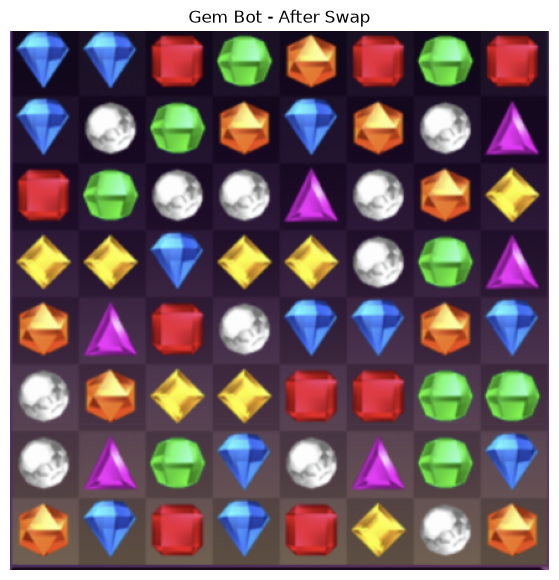

In [12]:

# ==========================================
# GEM BOT - AUTO SWAP TEST
# 自動交換一次寶石
# ==========================================

# 1. 確認棋盤與最佳移動
if not best_moves:
    raise ValueError("沒有有效移動，停止操作")

if np.any(board == "?"):
    raise ValueError("棋盤辨識不完整，停止操作")

best = best_moves[0]

r1, c1 = best["from"]
r2, c2 = best["to"]

# 2. 計算最新滑鼠座標
start_x = int(board_x + (c1 + 0.5) * cell_w)
start_y = int(board_y + (r1 + 0.5) * cell_h)

end_x = int(board_x + (c2 + 0.5) * cell_w)
end_y = int(board_y + (r2 + 0.5) * cell_h)

print("========== AUTO SWAP ==========")
print("交換位置：", best["from"], "->", best["to"])
print("預期消除：", best["score"], "顆")

# 3. 執行滑鼠拖曳
pyg.moveTo(start_x, start_y, duration=0.2)
time.sleep(0.1)

pyg.mouseDown()

try:
    pyg.moveTo(end_x, end_y, duration=0.35)
    time.sleep(0.1)
finally:
    pyg.mouseUp()

print("滑鼠交換指令已送出！")

# 4. 等待消除及補入動畫
time.sleep(2.0)

# 5. 重新擷取棋盤
screen = capture_screen()

board_image = screen[
    board_y:board_y + board_h,
    board_x:board_x + board_w
]

# 6. 重新辨識全部寶石
new_board = []

for r in range(8):
    row = []

    for c in range(8):

        cx = int((c + 0.5) * cell_w)
        cy = int((r + 0.5) * cell_h)

        pw = int(cell_w * 0.4)
        ph = int(cell_h * 0.4)

        patch = board_image[
            cy-ph//2:cy+ph//2,
            cx-pw//2:cx+pw//2
        ]

        row.append(detect_gem_color(patch))

    new_board.append(row)

board = np.array(new_board)

# 7. 顯示結果
print("\n========== UPDATED BOARD ==========")

for row in board:
    print(" ".join(row))

unknown = np.sum(board == "?")

print("\n未知格數：", unknown)

# 8. 計算下一次最佳移動
if unknown == 0:

    best_moves = find_best_moves(board)

    print("\n========== NEXT MOVE ==========")

    if best_moves:
        for i, move in enumerate(best_moves[:5]):
            print(
                f"{i+1}. {move['from']} -> {move['to']} "
                f"| 消除 {move['score']} 顆"
            )
    else:
        print("目前沒有有效移動")

else:
    best_moves = []
    print("辨識不完整，暫停自動操作")

# 9. 顯示最新棋盤
plt.figure(figsize=(7, 7))

plt.imshow(
    cv2.cvtColor(board_image, cv2.COLOR_BGR2RGB)
)

plt.title("Gem Bot - After Swap")
plt.axis("off")
plt.show()


In [15]:

# ==========================================
# GEM BOT - AUTO PLAY ENGINE
# 60 秒自動刷分機器人
# ==========================================

import time

# 遊戲設定
RUN_SECONDS = 70
ANIMATION_WAIT = 0.6
DRAG_DURATION = 0.05

# 統計資料
move_count = 0
total_removed = 0
start_time = time.time()

print("=" * 45)
print("       GEM BOT AUTO PLAY START")
print("=" * 45)

try:

    while time.time() - start_time < RUN_SECONDS:

        # 1. 擷取最新畫面
        screen = capture_screen()

        board_image = screen[
            board_y:board_y + board_h,
            board_x:board_x + board_w
        ]

        # 2. 辨識棋盤
        current_board = []

        for r in range(8):

            row = []

            for c in range(8):

                cx = int((c + 0.5) * cell_w)
                cy = int((r + 0.5) * cell_h)

                pw = int(cell_w * 0.4)
                ph = int(cell_h * 0.4)

                patch = board_image[
                    cy-ph//2:cy+ph//2,
                    cx-pw//2:cx+pw//2
                ]

                row.append(detect_gem_color(patch))

            current_board.append(row)

        board = np.array(current_board)

        # 3. 檢查辨識結果
        if board.shape != (8, 8):
            print("棋盤尺寸異常，停止")
            break

        if np.any(board == "?"):
            print("辨識不完整，等待重新擷取")
            time.sleep(0.3)
            continue

        # 4. 尋找最佳移動
        best_moves = find_best_moves(board)

        if not best_moves:
            print("沒有有效移動，停止本次循環")
            break

        best = best_moves[0]

        r1, c1 = best["from"]
        r2, c2 = best["to"]

        # 5. 計算滑鼠座標
        start_x = int(
            board_x + (c1 + 0.5) * cell_w
        )

        start_y = int(
            board_y + (r1 + 0.5) * cell_h
        )

        end_x = int(
            board_x + (c2 + 0.5) * cell_w
        )

        end_y = int(
            board_y + (r2 + 0.5) * cell_h
        )

        # 6. 自動拖曳
        pyg.moveTo(start_x, start_y, duration=0.02)
        pyg.mouseDown()

        try:
            pyg.moveTo(
                end_x,
                end_y,
                duration=DRAG_DURATION
            )
        finally:
            pyg.mouseUp()

        move_count += 1
        total_removed += best["score"]

        # 7. 顯示執行狀態
        elapsed = time.time() - start_time
        remaining = max(0, RUN_SECONDS - elapsed)

        print(
            f"第 {move_count} 次 | "
            f"交換 {best['from']} -> {best['to']} | "
            f"預計消除 {best['score']} 顆 | "
            f"剩餘 {remaining:.1f} 秒"
        )

        # 8. 等待動畫
        time.sleep(ANIMATION_WAIT)

except KeyboardInterrupt:

    print("\n使用者手動停止機器人")

finally:

    # 確保滑鼠放開
    pyg.mouseUp()

    elapsed = time.time() - start_time

    print("\n" + "=" * 45)
    print("          GEM BOT REPORT")
    print("=" * 45)

    print("執行時間：", round(elapsed, 2), "秒")
    print("成功送出交換次數：", move_count)
    print("預估消除總數：", total_removed)

    if elapsed > 0:
        print(
            "平均每秒交換次數：",
            round(move_count / elapsed, 2)
        )

    print("\nGEM BOT 已停止！")


       GEM BOT AUTO PLAY START
第 1 次 | 交換 (3, 4) -> (4, 4) | 預計消除 21 顆 | 剩餘 69.7 秒
第 2 次 | 交換 (1, 1) -> (1, 2) | 預計消除 3 顆 | 剩餘 68.8 秒
第 3 次 | 交換 (5, 4) -> (5, 5) | 預計消除 6 顆 | 剩餘 68.0 秒
第 4 次 | 交換 (0, 1) -> (0, 2) | 預計消除 6 顆 | 剩餘 67.1 秒
第 5 次 | 交換 (1, 3) -> (1, 4) | 預計消除 6 顆 | 剩餘 66.2 秒
第 6 次 | 交換 (2, 3) -> (2, 4) | 預計消除 4 顆 | 剩餘 65.4 秒
第 7 次 | 交換 (0, 1) -> (1, 1) | 預計消除 3 顆 | 剩餘 64.5 秒
第 8 次 | 交換 (3, 2) -> (3, 3) | 預計消除 7 顆 | 剩餘 63.6 秒
第 9 次 | 交換 (2, 5) -> (3, 5) | 預計消除 4 顆 | 剩餘 62.8 秒
第 10 次 | 交換 (0, 1) -> (1, 1) | 預計消除 8 顆 | 剩餘 61.9 秒
第 11 次 | 交換 (0, 0) -> (0, 1) | 預計消除 3 顆 | 剩餘 61.0 秒
第 12 次 | 交換 (0, 2) -> (1, 2) | 預計消除 3 顆 | 剩餘 60.2 秒
第 13 次 | 交換 (1, 4) -> (2, 4) | 預計消除 6 顆 | 剩餘 59.3 秒
第 14 次 | 交換 (0, 0) -> (1, 0) | 預計消除 7 顆 | 剩餘 58.4 秒
第 15 次 | 交換 (0, 0) -> (1, 0) | 預計消除 3 顆 | 剩餘 57.5 秒
第 16 次 | 交換 (0, 0) -> (1, 0) | 預計消除 3 顆 | 剩餘 56.7 秒
第 17 次 | 交換 (0, 2) -> (1, 2) | 預計消除 6 顆 | 剩餘 55.8 秒
第 18 次 | 交換 (0, 2) -> (1, 2) | 預計消除 3 顆 | 剩餘 54.9 秒
第 19 次 | 交換 (6, 2) -> (6, 3) | 預計消除 16 顆 

In [17]:

# ==========================================
# GEM BOT - SMART MOVE SOLVER
# 智慧最佳移動判斷
# ==========================================

def evaluate_move(board, r1, c1, r2, c2):

    new_board = board.copy()

    # 交換寶石
    new_board[r1, c1], new_board[r2, c2] = (
        new_board[r2, c2],
        new_board[r1, c1]
    )

    # 只檢查經過交換位置的消除組合
    positions = [(r1, c1), (r2, c2)]

    matched = set()
    runs = []

    for r, c in positions:

        color = new_board[r, c]

        if color == "?":
            continue

        # 橫向
        horizontal = [(r, c)]

        j = c - 1
        while j >= 0 and new_board[r, j] == color:
            horizontal.insert(0, (r, j))
            j -= 1

        j = c + 1
        while j < 8 and new_board[r, j] == color:
            horizontal.append((r, j))
            j += 1

        if len(horizontal) >= 3:
            runs.append(("H", horizontal))
            matched.update(horizontal)

        # 直向
        vertical = [(r, c)]

        j = r - 1
        while j >= 0 and new_board[j, c] == color:
            vertical.insert(0, (j, c))
            j -= 1

        j = r + 1
        while j < 8 and new_board[j, c] == color:
            vertical.append((j, c))
            j += 1

        if len(vertical) >= 3:
            runs.append(("V", vertical))
            matched.update(vertical)

    # 無有效消除
    if not matched:
        return None

    # 基礎分數：消除格數
    score = len(matched)

    # 特殊組合加權
    for direction, run in runs:

        length = len(run)

        if length == 4:
            score += 3

        elif length == 5:
            score += 8

        elif length >= 6:
            score += 12

    # 交叉消除額外獎勵
    horizontal_cells = set()
    vertical_cells = set()

    for direction, run in runs:

        if direction == "H":
            horizontal_cells.update(run)
        else:
            vertical_cells.update(run)

    intersections = (
        horizontal_cells & vertical_cells
    )

    score += len(intersections) * 5

    return {
        "from": (r1, c1),
        "to": (r2, c2),
        "score": score,
        "removed": len(matched),
        "matches": matched,
        "runs": runs,
        "intersections": intersections
    }


# ==========================================
# 搜尋所有有效移動
# ==========================================

def find_best_moves(board):

    board = np.array(board)

    if board.shape != (8, 8):
        raise ValueError("棋盤必須為 8x8")

    if np.any(board == "?"):
        raise ValueError("棋盤辨識不完整")

    results = []

    for r in range(8):
        for c in range(8):

            # 右邊
            if c + 1 < 8:

                move = evaluate_move(
                    board, r, c, r, c + 1
                )

                if move is not None:
                    results.append(move)

            # 下方
            if r + 1 < 8:

                move = evaluate_move(
                    board, r, c, r + 1, c
                )

                if move is not None:
                    results.append(move)

    # 依照加權分數排序
    results.sort(
        key=lambda x: (
            x["score"],
            x["removed"],
            len(x["intersections"])
        ),
        reverse=True
    )

    return results


# ==========================================
# 測試最佳移動
# ==========================================

best_moves = find_best_moves(board)

print("=" * 50)
print("       GEM BOT - SMART ANALYSIS")
print("=" * 50)

if best_moves:

    for i, move in enumerate(best_moves[:10]):

        print(f"\n第 {i+1} 名")
        print("交換位置：", move["from"], "→", move["to"])
        print("實際消除：", move["removed"], "顆")
        print("加權策略分數：", move["score"])
        print("交叉消除：", len(move["intersections"]), "格")

    print("\n最佳選擇：", best_moves[0]["from"],
          "→", best_moves[0]["to"])

else:
    print("目前沒有有效移動")


       GEM BOT - SMART ANALYSIS

第 1 名
交換位置： (6, 5) → (7, 5)
實際消除： 5 顆
加權策略分數： 10
交叉消除： 1 格

第 2 名
交換位置： (7, 4) → (7, 5)
實際消除： 5 顆
加權策略分數： 10
交叉消除： 1 格

第 3 名
交換位置： (3, 5) → (4, 5)
實際消除： 4 顆
加權策略分數： 7
交叉消除： 0 格

第 4 名
交換位置： (0, 1) → (0, 2)
實際消除： 3 顆
加權策略分數： 3
交叉消除： 0 格

第 5 名
交換位置： (0, 5) → (0, 6)
實際消除： 3 顆
加權策略分數： 3
交叉消除： 0 格

第 6 名
交換位置： (0, 5) → (1, 5)
實際消除： 3 顆
加權策略分數： 3
交叉消除： 0 格

第 7 名
交換位置： (1, 3) → (2, 3)
實際消除： 3 顆
加權策略分數： 3
交叉消除： 0 格

第 8 名
交換位置： (3, 6) → (4, 6)
實際消除： 3 顆
加權策略分數： 3
交叉消除： 0 格

第 9 名
交換位置： (4, 5) → (4, 6)
實際消除： 3 顆
加權策略分數： 3
交叉消除： 0 格

第 10 名
交換位置： (5, 1) → (5, 2)
實際消除： 3 顆
加權策略分數： 3
交叉消除： 0 格

最佳選擇： (6, 5) → (7, 5)


執行移動： (5, 4) → (6, 4)
預期消除： 4 顆


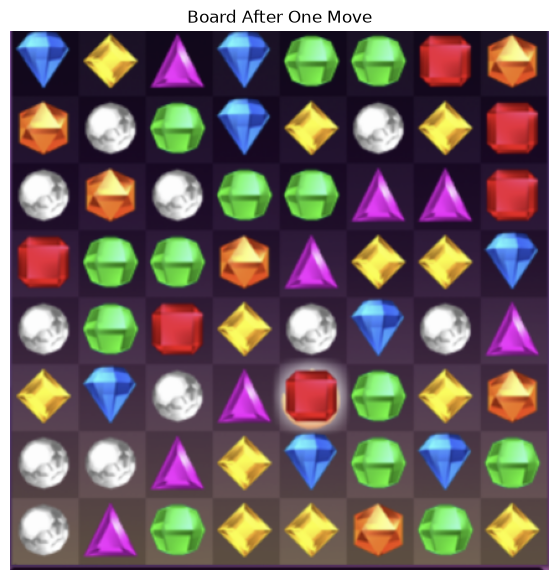

In [18]:
# ==========================================
# GEM BOT - ONE MOVE TEST
# 實際測試消除與補珠機制
# ==========================================

# 重新擷取目前棋盤
screen = capture_screen()

board_image = screen[
    board_y:board_y + board_h,
    board_x:board_x + board_w
]

# 重新辨識
new_board = []

for r in range(8):
    row = []

    for c in range(8):

        cx = int((c + 0.5) * cell_w)
        cy = int((r + 0.5) * cell_h)

        pw = int(cell_w * 0.4)
        ph = int(cell_h * 0.4)

        patch = board_image[
            cy-ph//2:cy+ph//2,
            cx-pw//2:cx+pw//2
        ]

        row.append(detect_gem_color(patch))

    new_board.append(row)

board = np.array(new_board)

# 檢查棋盤
if np.any(board == "?"):
    raise ValueError("棋盤辨識不完整，停止測試")

# 計算最佳移動
best_moves = find_best_moves(board)

if not best_moves:
    print("沒有可執行的移動")

else:

    best = best_moves[0]

    r1, c1 = best["from"]
    r2, c2 = best["to"]

    start_x = int(board_x + (c1 + 0.5) * cell_w)
    start_y = int(board_y + (r1 + 0.5) * cell_h)

    end_x = int(board_x + (c2 + 0.5) * cell_w)
    end_y = int(board_y + (r2 + 0.5) * cell_h)

    print("執行移動：", best["from"], "→", best["to"])
    print("預期消除：", best["removed"], "顆")

    # 執行一次拖曳
    pyg.moveTo(start_x, start_y, duration=0.1)
    pyg.mouseDown()

    try:
        pyg.moveTo(end_x, end_y, duration=0.15)
    finally:
        pyg.mouseUp()

    # 等待遊戲反應
    time.sleep(2)

    # 擷取消除後畫面
    after_screen = capture_screen()

    after_board = after_screen[
        board_y:board_y + board_h,
        board_x:board_x + board_w
    ]

    plt.figure(figsize=(7, 7))
    plt.imshow(cv2.cvtColor(after_board, cv2.COLOR_BGR2RGB))
    plt.title("Board After One Move")
    plt.axis("off")
    plt.show()

In [19]:

# ==========================================
# GEM BOT - SMART SOLVER 2.0
# 蒙地卡羅隨機補珠與連鎖消除模擬
# ==========================================

import numpy as np

# 模擬設定
SIMULATIONS = 30
MAX_CASCADES = 8


# ==========================================
# 1. 模擬寶石掉落與隨機補珠
# ==========================================

def drop_and_refill(board, colors, rng):

    new_board = board.copy()

    for c in range(8):

        # 保留原本未消除的寶石
        remaining = [
            new_board[r, c]
            for r in range(8)
            if new_board[r, c] != "."
        ]

        empty_count = 8 - len(remaining)

        # 隨機產生新寶石
        new_gems = rng.choice(
            colors,
            size=empty_count
        ).tolist()

        # 新寶石放在上方
        column = new_gems + remaining

        for r in range(8):
            new_board[r, c] = column[r]

    return new_board


# ==========================================
# 2. 模擬消除與連鎖反應
# ==========================================

def simulate_cascade(board, colors, rng):

    current = board.copy()

    total_removed = 0
    cascade_count = 0

    for _ in range(MAX_CASCADES):

        matches = find_matches(current)

        if not matches:
            break

        # 消除寶石
        for r, c in matches:
            current[r, c] = "."

        removed = len(matches)
        total_removed += removed
        cascade_count += 1

        # 下落與隨機補珠
        current = drop_and_refill(
            current,
            colors,
            rng
        )

    return total_removed, cascade_count


# ==========================================
# 3. 模擬單次交換
# ==========================================

def simulate_move(board, move, colors, rng):

    new_board = board.copy()

    r1, c1 = move["from"]
    r2, c2 = move["to"]

    # 交換寶石
    new_board[r1, c1], new_board[r2, c2] = (
        new_board[r2, c2],
        new_board[r1, c1]
    )

    matches = find_matches(new_board)

    # 排除無效移動
    if not matches:
        return 0, 0

    if (r1, c1) not in matches and (r2, c2) not in matches:
        return 0, 0

    # 第一次消除
    for r, c in matches:
        new_board[r, c] = "."

    first_removed = len(matches)

    # 模擬重力與隨機補珠後的連鎖
    new_board = drop_and_refill(
        new_board,
        colors,
        rng
    )

    chain_removed, chain_count = simulate_cascade(
        new_board,
        colors,
        rng
    )

    return (
        first_removed + chain_removed,
        chain_count
    )


# ==========================================
# 4. 蒙地卡羅最佳移動搜尋
# ==========================================

def find_smart_moves(board, simulations=SIMULATIONS):

    board = np.array(board)

    if board.shape != (8, 8):
        raise ValueError("棋盤必須為 8x8")

    if np.any(board == "?"):
        raise ValueError("棋盤有未知寶石")

    # 根據目前棋盤估計各顏色出現機率
    colors, counts = np.unique(
        board,
        return_counts=True
    )

    probabilities = counts / counts.sum()

    results = []

    # 建立候選移動
    for r in range(8):
        for c in range(8):

            neighbors = []

            if c + 1 < 8:
                neighbors.append((r, c + 1))

            if r + 1 < 8:
                neighbors.append((r + 1, c))

            for nr, nc in neighbors:

                test = board.copy()

                test[r, c], test[nr, nc] = (
                    test[nr, nc],
                    test[r, c]
                )

                matches = find_matches(test)

                if not matches:
                    continue

                if (r, c) not in matches and (nr, nc) not in matches:
                    continue

                results.append({
                    "from": (r, c),
                    "to": (nr, nc),
                    "immediate": len(matches)
                })

    # 模擬每一個候選移動
    evaluated = []

    for move in results:

        total_scores = []
        total_chains = 0

        for _ in range(simulations):

            rng = np.random.default_rng()

            score, chains = simulate_move(
                board,
                move,
                colors,
                rng
            )

            total_scores.append(score)
            total_chains += chains

        average_score = np.mean(total_scores)

        chain_probability = (
            np.sum(np.array(total_scores) > move["immediate"])
            / simulations
        )

        evaluated.append({
            **move,
            "average_score": round(float(average_score), 2),
            "chain_probability": round(float(chain_probability), 3),
            "average_chains": round(
                total_chains / simulations, 2
            )
        })

    # 依照預期總消除數排序
    evaluated.sort(
        key=lambda x: (
            x["average_score"],
            x["immediate"]
        ),
        reverse=True
    )

    return evaluated


# ==========================================
# 5. 執行智慧分析
# ==========================================

smart_moves = find_smart_moves(
    board,
    simulations=SIMULATIONS
)

print("=" * 55)
print("       GEM BOT - MONTE CARLO ANALYSIS")
print("=" * 55)

if smart_moves:

    for i, move in enumerate(smart_moves[:10]):

        print(f"\n第 {i+1} 名")
        print("交換位置：", move["from"], "→", move["to"])
        print("立即消除：", move["immediate"], "顆")
        print("預期總消除：", move["average_score"], "顆")
        print("連鎖發生機率：",
              f"{move['chain_probability'] * 100:.1f}%")
        print("平均連鎖次數：", move["average_chains"])

    print("\n最佳策略：",
          smart_moves[0]["from"],
          "→",
          smart_moves[0]["to"])

else:
    print("目前沒有有效移動")


       GEM BOT - MONTE CARLO ANALYSIS

第 1 名
交換位置： (2, 1) → (2, 2)
立即消除： 3 顆
預期總消除： 7.6 顆
連鎖發生機率： 100.0%
平均連鎖次數： 1.33

第 2 名
交換位置： (1, 5) → (2, 5)
立即消除： 3 顆
預期總消除： 4.6 顆
連鎖發生機率： 33.3%
平均連鎖次數： 0.5

第 3 名
交換位置： (1, 2) → (1, 3)
立即消除： 3 顆
預期總消除： 4.4 顆
連鎖發生機率： 36.7%
平均連鎖次數： 0.4

第 4 名
交換位置： (5, 4) → (6, 4)
立即消除： 4 顆
預期總消除： 4.3 顆
連鎖發生機率： 6.7%
平均連鎖次數： 0.1

第 5 名
交換位置： (1, 0) → (2, 0)
立即消除： 3 顆
預期總消除： 3.5 顆
連鎖發生機率： 16.7%
平均連鎖次數： 0.17

第 6 名
交換位置： (2, 5) → (2, 6)
立即消除： 3 顆
預期總消除： 3.4 顆
連鎖發生機率： 13.3%
平均連鎖次數： 0.13

第 7 名
交換位置： (0, 6) → (0, 7)
立即消除： 3 顆
預期總消除： 3.3 顆
連鎖發生機率： 10.0%
平均連鎖次數： 0.1

第 8 名
交換位置： (1, 3) → (2, 3)
立即消除： 3 顆
預期總消除： 3.2 顆
連鎖發生機率： 6.7%
平均連鎖次數： 0.07

第 9 名
交換位置： (4, 0) → (5, 0)
立即消除： 3 顆
預期總消除： 3.2 顆
連鎖發生機率： 6.7%
平均連鎖次數： 0.07

第 10 名
交換位置： (0, 3) → (1, 3)
立即消除： 3 顆
預期總消除： 3.1 顆
連鎖發生機率： 3.3%
平均連鎖次數： 0.03

最佳策略： (2, 1) → (2, 2)


In [20]:

# ============================================================
# GEM BOT - SMART SOLVER 2.0
# 蒙地卡羅模擬：隨機補珠、重力下落、連鎖消除
# ============================================================

import numpy as np

# =========================
# 1. 模擬參數
# =========================

SIMULATIONS = 300
MAX_CASCADES = 8
BOARD_SIZE = 8

# =========================
# 2. 判斷棋盤上的消除組合
# =========================

def find_matches(board):

    rows, cols = board.shape
    matched = set()

    # 橫向檢查
    for r in range(rows):

        c = 0

        while c < cols:

            start = c
            color = board[r, c]

            while c < cols and board[r, c] == color:
                c += 1

            length = c - start

            if color != "." and length >= 3:
                for k in range(start, c):
                    matched.add((r, k))

    # 縱向檢查
    for c in range(cols):

        r = 0

        while r < rows:

            start = r
            color = board[r, c]

            while r < rows and board[r, c] == color:
                r += 1

            length = r - start

            if color != "." and length >= 3:
                for k in range(start, r):
                    matched.add((k, c))

    return matched


# =========================
# 3. 寶石下落與隨機補珠
# =========================

def drop_and_refill(board, colors, probabilities, rng):

    new_board = board.copy()

    for c in range(BOARD_SIZE):

        # 收集沒有被消除的寶石
        remaining = [
            new_board[r, c]
            for r in range(BOARD_SIZE)
            if new_board[r, c] != "."
        ]

        # 計算需要補入的寶石數量
        empty_count = BOARD_SIZE - len(remaining)

        # 根據目前棋盤顏色比例隨機補珠
        new_gems = rng.choice(
            colors,
            size=empty_count,
            p=probabilities
        ).tolist()

        # 新寶石從上方進入
        column = new_gems + remaining

        for r in range(BOARD_SIZE):
            new_board[r, c] = column[r]

    return new_board


# =========================
# 4. 模擬連鎖消除
# =========================

def simulate_cascade(
    board,
    colors,
    probabilities,
    rng
):

    current = board.copy()

    total_removed = 0
    cascade_count = 0

    for _ in range(MAX_CASCADES):

        matches = find_matches(current)

        if not matches:
            break

        # 消除符合條件的寶石
        for r, c in matches:
            current[r, c] = "."

        total_removed += len(matches)
        cascade_count += 1

        # 下落並補入新寶石
        current = drop_and_refill(
            current,
            colors,
            probabilities,
            rng
        )

    return total_removed, cascade_count


# =========================
# 5. 模擬一次交換
# =========================

def simulate_move(
    board,
    move,
    colors,
    probabilities,
    rng
):

    new_board = board.copy()

    r1, c1 = move["from"]
    r2, c2 = move["to"]

    # 交換寶石
    new_board[r1, c1], new_board[r2, c2] = (
        new_board[r2, c2],
        new_board[r1, c1]
    )

    matches = find_matches(new_board)

    # 確認交換後有形成消除
    if not matches:
        return 0, 0

    if (r1, c1) not in matches and (r2, c2) not in matches:
        return 0, 0

    # 第一次消除
    first_removed = len(matches)

    for r, c in matches:
        new_board[r, c] = "."

    # 下落與隨機補珠
    new_board = drop_and_refill(
        new_board,
        colors,
        probabilities,
        rng
    )

    # 模擬後續連鎖
    chain_removed, chain_count = simulate_cascade(
        new_board,
        colors,
        probabilities,
        rng
    )

    total_removed = first_removed + chain_removed

    return total_removed, chain_count


# =========================
# 6. 搜尋所有有效移動
# =========================

def get_valid_moves(board):

    moves = []

    for r in range(BOARD_SIZE):
        for c in range(BOARD_SIZE):

            neighbors = []

            if c + 1 < BOARD_SIZE:
                neighbors.append((r, c + 1))

            if r + 1 < BOARD_SIZE:
                neighbors.append((r + 1, c))

            for nr, nc in neighbors:

                test = board.copy()

                test[r, c], test[nr, nc] = (
                    test[nr, nc],
                    test[r, c]
                )

                matches = find_matches(test)

                if not matches:
                    continue

                if (r, c) not in matches and (nr, nc) not in matches:
                    continue

                moves.append({
                    "from": (r, c),
                    "to": (nr, nc),
                    "immediate": len(matches)
                })

    return moves


# =========================
# 7. 蒙地卡羅智慧策略
# =========================

def find_smart_moves(
    board,
    simulations=SIMULATIONS
):

    board = np.array(board, dtype=str)

    if board.shape != (BOARD_SIZE, BOARD_SIZE):
        raise ValueError("棋盤必須是 8×8")

    if np.any(board == "?"):
        raise ValueError("棋盤存在未知寶石，請重新辨識")

    if np.any(board == "."):
        raise ValueError("棋盤存在空格，請等待寶石補齊後重新辨識")

    # 根據目前棋盤估算各種寶石的出現機率
    colors, counts = np.unique(
        board,
        return_counts=True
    )

    probabilities = counts / counts.sum()

    # 搜尋所有有效移動
    candidates = get_valid_moves(board)

    evaluated = []

    for index, move in enumerate(candidates):

        total_scores = []
        total_chains = 0

        # 每個候選移動進行多次模擬
        rng = np.random.default_rng()

        for _ in range(simulations):

            score, chains = simulate_move(
                board,
                move,
                colors,
                probabilities,
                rng
            )

            total_scores.append(score)
            total_chains += chains

        scores = np.array(total_scores)

        average_score = float(np.mean(scores))

        chain_probability = float(
            np.mean(scores > move["immediate"])
        )

        average_chains = (
            total_chains / simulations
        )

        evaluated.append({
            "from": move["from"],
            "to": move["to"],
            "immediate": move["immediate"],
            "average_score": round(average_score, 2),
            "chain_probability": round(chain_probability, 3),
            "average_chains": round(average_chains, 2)
        })

    # 依照預期消除收益排序
    evaluated.sort(
        key=lambda x: (
            x["average_score"],
            x["immediate"]
        ),
        reverse=True
    )

    return evaluated


# =========================
# 8. 執行策略分析
# =========================

if "board" not in globals():

    print("錯誤：目前沒有 board 棋盤資料，請先執行棋盤辨識程式。")

else:

    smart_moves = find_smart_moves(
        board,
        simulations=SIMULATIONS
    )

    print("=" * 60)
    print("          GEM BOT - MONTE CARLO ANALYSIS")
    print("=" * 60)

    print("模擬次數：", SIMULATIONS)
    print("候選移動數：", len(smart_moves))

    if smart_moves:

        for i, move in enumerate(smart_moves[:10]):

            r1, c1 = move["from"]
            r2, c2 = move["to"]

            print(f"\n第 {i + 1} 名")

            print(
                f"交換位置：第 {r1+1} 列第 {c1+1} 欄"
                f" → 第 {r2+1} 列第 {c2+1} 欄"
            )

            print("立即消除：", move["immediate"], "顆")

            print(
                "預期總消除：",
                move["average_score"],
                "顆"
            )

            print(
                "連鎖發生機率：",
                f"{move['chain_probability'] * 100:.1f}%"
            )

            print(
                "平均連鎖次數：",
                move["average_chains"]
            )

        best = smart_moves[0]

        print("\n" + "=" * 60)
        print("最佳策略")
        print("交換位置：", best["from"], "→", best["to"])
        print("預期消除：", best["average_score"], "顆")
        print("=" * 60)

    else:
        print("目前沒有找到有效移動。")


          GEM BOT - MONTE CARLO ANALYSIS
模擬次數： 300
候選移動數： 13

第 1 名
交換位置：第 3 列第 2 欄 → 第 3 列第 3 欄
立即消除： 3 顆
預期總消除： 7.92 顆
連鎖發生機率： 100.0%
平均連鎖次數： 1.37

第 2 名
交換位置：第 6 列第 5 欄 → 第 7 列第 5 欄
立即消除： 4 顆
預期總消除： 4.29 顆
連鎖發生機率： 8.3%
平均連鎖次數： 0.09

第 3 名
交換位置：第 2 列第 3 欄 → 第 2 列第 4 欄
立即消除： 3 顆
預期總消除： 3.97 顆
連鎖發生機率： 29.0%
平均連鎖次數： 0.31

第 4 名
交換位置：第 2 列第 1 欄 → 第 3 列第 1 欄
立即消除： 3 顆
預期總消除： 3.96 顆
連鎖發生機率： 23.0%
平均連鎖次數： 0.3

第 5 名
交換位置：第 2 列第 6 欄 → 第 3 列第 6 欄
立即消除： 3 顆
預期總消除： 3.85 顆
連鎖發生機率： 23.3%
平均連鎖次數： 0.27

第 6 名
交換位置：第 5 列第 1 欄 → 第 6 列第 1 欄
立即消除： 3 顆
預期總消除： 3.64 顆
連鎖發生機率： 17.7%
平均連鎖次數： 0.21

第 7 名
交換位置：第 6 列第 5 欄 → 第 6 列第 6 欄
立即消除： 3 顆
預期總消除： 3.31 顆
連鎖發生機率： 9.3%
平均連鎖次數： 0.1

第 8 名
交換位置：第 1 列第 4 欄 → 第 2 列第 4 欄
立即消除： 3 顆
預期總消除： 3.29 顆
連鎖發生機率： 8.3%
平均連鎖次數： 0.09

第 9 名
交換位置：第 2 列第 4 欄 → 第 3 列第 4 欄
立即消除： 3 顆
預期總消除： 3.29 顆
連鎖發生機率： 8.7%
平均連鎖次數： 0.1

第 10 名
交換位置：第 7 列第 7 欄 → 第 8 列第 7 欄
立即消除： 3 顆
預期總消除： 3.17 顆
連鎖發生機率： 5.0%
平均連鎖次數： 0.05

最佳策略
交換位置： (2, 1) → (2, 2)
預期消除： 7.92 顆


In [21]:

# ============================================================
# GEM BOT 3.0 - MONTE CARLO AUTO PLAY ENGINE
# 蒙地卡羅智慧策略 + 自動辨識 + 自動拖曳
# ============================================================

import time
import numpy as np
import pyautogui as pyg

# =========================
# 1. 遊戲設定
# =========================

RUN_SECONDS = 70

SIMULATIONS = 300

ANIMATION_WAIT = 1.0
DRAG_DURATION = 0.05

MAX_MOVES = 100

# =========================
# 2. 統計資料
# =========================

move_count = 0
total_immediate_removed = 0
total_predicted_removed = 0

start_time = time.time()

print("=" * 55)
print("       GEM BOT 3.0 - SMART AUTO PLAY")
print("=" * 55)

print("模擬次數：", SIMULATIONS)
print("執行時間：", RUN_SECONDS, "秒")

# =========================
# 3. 自動遊戲主迴圈
# =========================

try:

    while (
        time.time() - start_time < RUN_SECONDS
        and move_count < MAX_MOVES
    ):

        # -------------------------
        # A. 擷取最新畫面
        # -------------------------

        screen = capture_screen()

        board_image = screen[
            board_y:board_y + board_h,
            board_x:board_x + board_w
        ]

        # -------------------------
        # B. 辨識 8x8 棋盤
        # -------------------------

        current_board = []

        for r in range(8):

            row = []

            for c in range(8):

                cx = int((c + 0.5) * cell_w)
                cy = int((r + 0.5) * cell_h)

                pw = int(cell_w * 0.4)
                ph = int(cell_h * 0.4)

                patch = board_image[
                    cy-ph//2:cy+ph//2,
                    cx-pw//2:cx+pw//2
                ]

                row.append(
                    detect_gem_color(patch)
                )

            current_board.append(row)

        board = np.array(current_board)

        # -------------------------
        # C. 檢查棋盤狀態
        # -------------------------

        if board.shape != (8, 8):

            print("棋盤尺寸異常，停止操作")
            break

        if np.any(board == "?"):

            print("棋盤辨識不完整，重新擷取")
            time.sleep(0.3)
            continue

        if np.any(board == "."):

            print("棋盤尚未補滿，等待動畫")
            time.sleep(0.5)
            continue

        # -------------------------
        # D. 蒙地卡羅智慧策略
        # -------------------------

        print("\n正在分析最佳移動...")

        best_moves = find_smart_moves(
            board,
            simulations=SIMULATIONS
        )

        if not best_moves:

            print("目前沒有有效移動")
            break

        best = best_moves[0]

        r1, c1 = best["from"]
        r2, c2 = best["to"]

        # -------------------------
        # E. 計算滑鼠座標
        # -------------------------

        start_x = int(
            board_x + (c1 + 0.5) * cell_w
        )

        start_y = int(
            board_y + (r1 + 0.5) * cell_h
        )

        end_x = int(
            board_x + (c2 + 0.5) * cell_w
        )

        end_y = int(
            board_y + (r2 + 0.5) * cell_h
        )

        # -------------------------
        # F. 執行交換
        # -------------------------

        pyg.moveTo(
            start_x,
            start_y,
            duration=0.02
        )

        pyg.mouseDown()

        try:

            pyg.moveTo(
                end_x,
                end_y,
                duration=DRAG_DURATION
            )

        finally:

            pyg.mouseUp()

        move_count += 1

        total_immediate_removed += best["immediate"]

        total_predicted_removed += best["average_score"]

        # -------------------------
        # G. 顯示策略結果
        # -------------------------

        elapsed = time.time() - start_time

        remaining = max(
            0,
            RUN_SECONDS - elapsed
        )

        print("-" * 45)

        print("第", move_count, "次交換")

        print(
            f"交換位置：第 {r1+1} 列第 {c1+1} 欄"
            f" → 第 {r2+1} 列第 {c2+1} 欄"
        )

        print(
            "立即消除：",
            best["immediate"],
            "顆"
        )

        print(
            "預期總消除：",
            best["average_score"],
            "顆"
        )

        print(
            "連鎖機率：",
            f"{best['chain_probability'] * 100:.1f}%"
        )

        print(
            "平均連鎖次數：",
            best["average_chains"]
        )

        print(
            "剩餘時間：",
            round(remaining, 1),
            "秒"
        )

        # -------------------------
        # H. 等待消除、掉落與補珠
        # -------------------------

        time.sleep(ANIMATION_WAIT)

except KeyboardInterrupt:

    print("\n使用者手動停止機器人")

except Exception as e:

    print("\n程式發生錯誤：", e)

finally:

    # 確保滑鼠放開
    pyg.mouseUp()

    elapsed = time.time() - start_time

    # =========================
    # 4. 最終執行報告
    # =========================

    print("\n" + "=" * 55)
    print("          GEM BOT 3.0 REPORT")
    print("=" * 55)

    print(
        "實際執行時間：",
        round(elapsed, 2),
        "秒"
    )

    print(
        "成功送出交換次數：",
        move_count
    )

    print(
        "每次移動的立即消除數合計：",
        total_immediate_removed
    )

    print(
        "預期消除總數合計：",
        round(total_predicted_removed, 2)
    )

    if elapsed > 0:

        print(
            "平均每秒交換次數：",
            round(move_count / elapsed, 2)
        )

    print("\nGEM BOT 3.0 已停止！")


       GEM BOT 3.0 - SMART AUTO PLAY
模擬次數： 300
執行時間： 70 秒

正在分析最佳移動...
---------------------------------------------
第 1 次交換
交換位置：第 7 列第 3 欄 → 第 8 列第 3 欄
立即消除： 30 顆
預期總消除： 43.55 顆
連鎖機率： 96.0%
平均連鎖次數： 1.94
剩餘時間： 49.4 秒

正在分析最佳移動...
---------------------------------------------
第 2 次交換
交換位置：第 4 列第 3 欄 → 第 4 列第 4 欄
立即消除： 3 顆
預期總消除： 10.27 顆
連鎖機率： 100.0%
平均連鎖次數： 1.69
剩餘時間： 44.8 秒

正在分析最佳移動...
---------------------------------------------
第 3 次交換
交換位置：第 5 列第 6 欄 → 第 6 列第 6 欄
立即消除： 43 顆
預期總消除： 67.18 顆
連鎖機率： 100.0%
平均連鎖次數： 2.68
剩餘時間： 16.4 秒

正在分析最佳移動...

使用者手動停止機器人

          GEM BOT 3.0 REPORT
實際執行時間： 59.28 秒
成功送出交換次數： 3
每次移動的立即消除數合計： 76
預期消除總數合計： 121.0
平均每秒交換次數： 0.05

GEM BOT 3.0 已停止！


In [40]:
# ==========================================
# GEM BOT - AUTO PLAY ENGINE
# 60 秒自動刷分機器人
# ==========================================

import time

# 遊戲設定
RUN_SECONDS = 63
ANIMATION_WAIT = 0.7
DRAG_DURATION = 0.05

# 統計資料
move_count = 0
total_removed = 0
start_time = time.time()

print("=" * 45)
print("       GEM BOT AUTO PLAY START")
print("=" * 45)

try:

    while time.time() - start_time < RUN_SECONDS:

        # 1. 擷取最新畫面
        screen = capture_screen()

        board_image = screen[
            board_y:board_y + board_h,
            board_x:board_x + board_w
        ]

        # 2. 辨識棋盤
        current_board = []

        for r in range(8):

            row = []

            for c in range(8):

                cx = int((c + 0.5) * cell_w)
                cy = int((r + 0.5) * cell_h)

                pw = int(cell_w * 0.4)
                ph = int(cell_h * 0.4)

                patch = board_image[
                    cy-ph//2:cy+ph//2,
                    cx-pw//2:cx+pw//2
                ]

                row.append(detect_gem_color(patch))

            current_board.append(row)

        board = np.array(current_board)

        # 3. 檢查辨識結果
        if board.shape != (8, 8):
            print("棋盤尺寸異常，停止")
            break

        if np.any(board == "?"):
            print("辨識不完整，等待重新擷取")
            time.sleep(0.3)
            continue

        # 4. 尋找最佳移動
        best_moves = find_best_moves(board)

        if not best_moves:
            print("沒有有效移動，停止本次循環")
            break

        best = best_moves[0]

        r1, c1 = best["from"]
        r2, c2 = best["to"]

        # 5. 計算滑鼠座標
        start_x = int(
            board_x + (c1 + 0.5) * cell_w
        )

        start_y = int(
            board_y + (r1 + 0.5) * cell_h
        )

        end_x = int(
            board_x + (c2 + 0.5) * cell_w
        )

        end_y = int(
            board_y + (r2 + 0.5) * cell_h
        )

        # 6. 自動拖曳
        pyg.moveTo(start_x, start_y, duration=0.02)
        pyg.mouseDown()

        try:
            pyg.moveTo(
                end_x,
                end_y,
                duration=DRAG_DURATION
            )
        finally:
            pyg.mouseUp()

        move_count += 1
        total_removed += best["score"]

        # 7. 顯示執行狀態
        elapsed = time.time() - start_time
        remaining = max(0, RUN_SECONDS - elapsed)

        print(
            f"第 {move_count} 次 | "
            f"交換 {best['from']} -> {best['to']} | "
            f"預計消除 {best['score']} 顆 | "
            f"剩餘 {remaining:.1f} 秒"
        )

        # 8. 等待動畫
        time.sleep(ANIMATION_WAIT)

except KeyboardInterrupt:

    print("\n使用者手動停止機器人")

finally:

    # 確保滑鼠放開
    pyg.mouseUp()

    elapsed = time.time() - start_time

    print("\n" + "=" * 45)
    print("          GEM BOT REPORT")
    print("=" * 45)

    print("執行時間：", round(elapsed, 2), "秒")
    print("成功送出交換次數：", move_count)
    print("預估消除總數：", total_removed)

    if elapsed > 0:
        print(
            "平均每秒交換次數：",
            round(move_count / elapsed, 2)
        )

    print("\nGEM BOT 已停止！")

       GEM BOT AUTO PLAY START
第 1 次 | 交換 (2, 2) -> (2, 3) | 預計消除 3 顆 | 剩餘 62.7 秒
第 2 次 | 交換 (0, 3) -> (1, 3) | 預計消除 10 顆 | 剩餘 61.8 秒
第 3 次 | 交換 (6, 2) -> (7, 2) | 預計消除 3 顆 | 剩餘 60.8 秒
第 4 次 | 交換 (3, 1) -> (3, 2) | 預計消除 3 顆 | 剩餘 59.9 秒
第 5 次 | 交換 (0, 1) -> (1, 1) | 預計消除 21 顆 | 剩餘 58.9 秒
第 6 次 | 交換 (3, 3) -> (4, 3) | 預計消除 3 顆 | 剩餘 57.9 秒
第 7 次 | 交換 (0, 3) -> (0, 4) | 預計消除 3 顆 | 剩餘 57.0 秒
第 8 次 | 交換 (3, 3) -> (3, 4) | 預計消除 7 顆 | 剩餘 56.0 秒
第 9 次 | 交換 (3, 2) -> (3, 3) | 預計消除 3 顆 | 剩餘 55.1 秒
第 10 次 | 交換 (3, 1) -> (3, 2) | 預計消除 3 顆 | 剩餘 54.1 秒
第 11 次 | 交換 (0, 1) -> (0, 2) | 預計消除 3 顆 | 剩餘 53.2 秒
第 12 次 | 交換 (3, 1) -> (4, 1) | 預計消除 7 顆 | 剩餘 52.2 秒
第 13 次 | 交換 (0, 2) -> (1, 2) | 預計消除 3 顆 | 剩餘 51.3 秒
第 14 次 | 交換 (1, 2) -> (2, 2) | 預計消除 7 顆 | 剩餘 50.3 秒
第 15 次 | 交換 (1, 3) -> (2, 3) | 預計消除 3 顆 | 剩餘 49.4 秒
第 16 次 | 交換 (0, 4) -> (1, 4) | 預計消除 3 顆 | 剩餘 48.4 秒
第 17 次 | 交換 (2, 3) -> (3, 3) | 預計消除 3 顆 | 剩餘 47.5 秒
第 18 次 | 交換 (0, 2) -> (1, 2) | 預計消除 3 顆 | 剩餘 46.5 秒
第 19 次 | 交換 (4, 4) -> (5, 4) | 預計消除 3 顆 

In [43]:
%pip install pynput


   -------------------- ------------------- 1/2 [pynput]
   -------------------- ------------------- 1/2 [pynput]
   -------------------- ------------------- 1/2 [pynput]
   ---------------------------------------- 2/2 [pynput]

Note: you may need to restart the kernel to use updated packages.


In [44]:
from pynput import keyboard

print("ESC 鍵盤監聽套件安裝成功！")

ESC 鍵盤監聽套件安裝成功！


In [46]:

# ============================================================
# GEM BOT 3.1 - MONTE CARLO SMART AUTO PLAY ENGINE
# ESC 暫停 / ESC 再次按下恢復
# ============================================================

import time
import threading
import numpy as np
import pyautogui as pyg
from pynput import keyboard

# =========================
# 1. 遊戲設定
# =========================

RUN_SECONDS = 63
SIMULATIONS = 300

ANIMATION_WAIT = 1.0
DRAG_DURATION = 0.05

MAX_MOVES = 100

# =========================
# 2. 暫停控制
# =========================

pause_event = threading.Event()
pause_event.set()  # 初始為執行狀態

pressed_keys = set()

def on_key_press(key):

    if key in pressed_keys:
        return

    pressed_keys.add(key)

    if key == keyboard.Key.esc:

        if pause_event.is_set():

            pause_event.clear()
            pyg.mouseUp()
            print("\n[ESC] 機器人已暫停")

        else:

            pause_event.set()
            print("\n[ESC] 機器人恢復執行")

def on_key_release(key):

    pressed_keys.discard(key)

# 啟動鍵盤監聽
listener = keyboard.Listener(
    on_press=on_key_press,
    on_release=on_key_release
)

listener.start()

# =========================
# 3. 暫停等待函數
# =========================

def wait_if_paused():

    while not pause_event.is_set():

        pyg.mouseUp()
        time.sleep(0.1)

def safe_wait(seconds):

    end_time = time.time() + seconds

    while time.time() < end_time:

        wait_if_paused()

        time.sleep(
            min(0.1, end_time - time.time())
        )

# =========================
# 4. 確認必要函數及變數
# =========================

required_functions = [
    "capture_screen",
    "detect_gem_color",
    "find_matches",
    "drop_and_refill",
    "simulate_cascade",
    "simulate_move",
    "get_valid_moves",
    "find_smart_moves"
]

required_variables = [
    "board_x",
    "board_y",
    "board_w",
    "board_h",
    "cell_w",
    "cell_h"
]

missing = [
    name for name in required_functions
    if not callable(globals().get(name))
]

missing += [
    name for name in required_variables
    if name not in globals()
]

if missing:

    listener.stop()

    raise RuntimeError(
        "缺少必要函數或變數：" + str(missing)
    )

# =========================
# 5. 統計資料
# =========================

move_count = 0
total_immediate_removed = 0
total_predicted_removed = 0

start_time = time.time()

print("=" * 55)
print("       GEM BOT 3.1 - SMART AUTO PLAY")
print("=" * 55)

print("執行時間：", RUN_SECONDS, "秒")
print("模擬次數：", SIMULATIONS)
print("按 ESC 可暫停 / 再按 ESC 可恢復")

# =========================
# 6. 自動操作主迴圈
# =========================

try:

    while (
        time.time() - start_time < RUN_SECONDS
        and move_count < MAX_MOVES
    ):

        # 暫停檢查
        wait_if_paused()

        # -------------------------
        # A. 擷取最新畫面
        # -------------------------

        screen = capture_screen()

        board_image = screen[
            board_y:board_y + board_h,
            board_x:board_x + board_w
        ]

        if (
            board_image.shape[0] != board_h
            or board_image.shape[1] != board_w
        ):

            print("棋盤截取範圍異常，停止")
            break

        # -------------------------
        # B. 辨識棋盤
        # -------------------------

        current_board = []

        for r in range(8):

            row = []

            for c in range(8):

                cx = int((c + 0.5) * cell_w)
                cy = int((r + 0.5) * cell_h)

                pw = int(cell_w * 0.4)
                ph = int(cell_h * 0.4)

                patch = board_image[
                    cy-ph//2:cy+ph//2,
                    cx-pw//2:cx+pw//2
                ]

                row.append(
                    detect_gem_color(patch)
                )

            current_board.append(row)

        board = np.array(current_board)

        # -------------------------
        # C. 棋盤檢查
        # -------------------------

        if board.shape != (8, 8):

            print("棋盤尺寸異常")
            break

        if np.any(board == "?"):

            print("辨識不完整，重新擷取")
            safe_wait(0.3)
            continue

        if np.any(board == "."):

            print("棋盤尚未補滿")
            safe_wait(0.5)
            continue

        # -------------------------
        # D. 智慧策略分析
        # -------------------------

        wait_if_paused()

        print("\n正在分析最佳移動...")

        best_moves = find_smart_moves(
            board,
            simulations=SIMULATIONS
        )

        # 分析完成後再次檢查暫停
        wait_if_paused()

        if not best_moves:

            print("沒有有效移動")
            break

        best = best_moves[0]

        r1, c1 = best["from"]
        r2, c2 = best["to"]

        # -------------------------
        # E. 計算滑鼠座標
        # -------------------------

        start_x = int(
            board_x + (c1 + 0.5) * cell_w
        )

        start_y = int(
            board_y + (r1 + 0.5) * cell_h
        )

        end_x = int(
            board_x + (c2 + 0.5) * cell_w
        )

        end_y = int(
            board_y + (r2 + 0.5) * cell_h
        )

        # -------------------------
        # F. 執行拖曳
        # -------------------------

        wait_if_paused()

        pyg.moveTo(
            start_x,
            start_y,
            duration=0.1
        )

        pyg.mouseDown()

        try:

            pyg.moveTo(
                end_x,
                end_y,
                duration=DRAG_DURATION,
                tween=pyg.easeOutQuad
            )

        finally:

            pyg.mouseUp()

        move_count += 1

        total_immediate_removed += best["immediate"]

        total_predicted_removed += best["average_score"]

        # -------------------------
        # G. 顯示分析結果
        # -------------------------

        elapsed = time.time() - start_time

        remaining = max(
            0,
            RUN_SECONDS - elapsed
        )

        print("-" * 55)

        print("第", move_count, "次移動")

        print(
            f"交換位置：第 {r1+1} 列第 {c1+1} 欄"
            f" → 第 {r2+1} 列第 {c2+1} 欄"
        )

        print("立即消除：", best["immediate"], "顆")

        print("預期總消除：", best["average_score"], "顆")

        print(
            "連鎖發生機率：",
            f"{best['chain_probability'] * 100:.1f}%"
        )

        print("剩餘時間：", round(remaining, 1), "秒")

        # -------------------------
        # H. 等待動畫與補珠
        # -------------------------

        safe_wait(ANIMATION_WAIT)

except KeyboardInterrupt:

    print("\nNotebook 收到中斷指令")

except Exception as e:

    print("\n程式發生錯誤：", repr(e))

finally:

    pyg.mouseUp()

    listener.stop()

    elapsed = time.time() - start_time

    print("\n" + "=" * 55)
    print("          GEM BOT 3.1 REPORT")
    print("=" * 55)

    print("執行時間：", round(elapsed, 2), "秒")
    print("交換次數：", move_count)

    print(
        "立即消除數合計：",
        total_immediate_removed
    )

    print(
        "預期消除數合計：",
        round(total_predicted_removed, 2)
    )

    print("\nGEM BOT 3.1 已停止！")



[ESC] 機器人恢復執行
-------------------------------------------------------
第 2 次移動
交換位置：第 4 列第 6 欄 → 第 5 列第 6 欄
立即消除： 10 顆
預期總消除： 17.48 顆
連鎖發生機率： 100.0%
剩餘時間： 41.1 秒

正在分析最佳移動...

[ESC] 機器人已暫停

[ESC] 機器人恢復執行
-------------------------------------------------------
第 3 次移動
交換位置：第 8 列第 3 欄 → 第 8 列第 4 欄
立即消除： 6 顆
預期總消除： 8.0 顆
連鎖發生機率： 43.0%
剩餘時間： 35.6 秒

正在分析最佳移動...

[ESC] 機器人已暫停

Notebook 收到中斷指令

          GEM BOT 3.1 REPORT
執行時間： 32.62 秒
交換次數： 3
立即消除數合計： 26
預期消除數合計： 45.38

GEM BOT 3.1 已停止！


In [47]:

# ==========================================
# GEM BOT - REAL GAME TEST
# 實際移動與預測結果記錄
# ==========================================

import time
import numpy as np
import pyautogui as pyg

TEST_SECONDS = 30
SIMULATIONS = 300
ANIMATION_WAIT = 1.2

records = []
test_start = time.time()

print("=" * 50)
print("GEM BOT REAL GAME TEST")
print("按 ESC 暫停，再按 ESC 恢復")
print("=" * 50)

try:

    while time.time() - test_start < TEST_SECONDS:

        wait_if_paused()

        # 擷取目前棋盤
        screen = capture_screen()

        board_image = screen[
            board_y:board_y + board_h,
            board_x:board_x + board_w
        ]

        current_board = []

        for r in range(8):

            row = []

            for c in range(8):

                cx = int((c + 0.5) * cell_w)
                cy = int((r + 0.5) * cell_h)

                pw = int(cell_w * 0.4)
                ph = int(cell_h * 0.4)

                patch = board_image[
                    cy-ph//2:cy+ph//2,
                    cx-pw//2:cx+pw//2
                ]

                row.append(detect_gem_color(patch))

            current_board.append(row)

        board = np.array(current_board)

        if np.any(board == "?") or np.any(board == "."):
            print("棋盤尚未穩定，重新辨識")
            safe_wait(0.5)
            continue

        # 蒙地卡羅分析
        moves = find_smart_moves(
            board,
            simulations=SIMULATIONS
        )

        wait_if_paused()

        if not moves:
            print("沒有有效移動")
            break

        best = moves[0]

        r1, c1 = best["from"]
        r2, c2 = best["to"]

        # 計算座標
        sx = int(board_x + (c1 + 0.5) * cell_w)
        sy = int(board_y + (r1 + 0.5) * cell_h)

        ex = int(board_x + (c2 + 0.5) * cell_w)
        ey = int(board_y + (r2 + 0.5) * cell_h)

        # 執行交換
        pyg.moveTo(sx, sy, duration=0.1)
        pyg.mouseDown()

        try:
            pyg.moveTo(ex, ey, duration=0.05)
        finally:
            pyg.mouseUp()

        # 等待遊戲結算
        safe_wait(ANIMATION_WAIT)

        # 重新擷取棋盤
        after_screen = capture_screen()

        after_image = after_screen[
            board_y:board_y + board_h,
            board_x:board_x + board_w
        ]

        after_board = []

        for r in range(8):

            row = []

            for c in range(8):

                cx = int((c + 0.5) * cell_w)
                cy = int((r + 0.5) * cell_h)

                pw = int(cell_w * 0.4)
                ph = int(cell_h * 0.4)

                patch = after_image[
                    cy-ph//2:cy+ph//2,
                    cx-pw//2:cx+pw//2
                ]

                row.append(detect_gem_color(patch))

            after_board.append(row)

        after_board = np.array(after_board)

        # 記錄預測與實際畫面變化
        changed_cells = int(
            np.sum(board != after_board)
        )

        record = {
            "move": len(records) + 1,
            "from": best["from"],
            "to": best["to"],
            "predicted": best["average_score"],
            "immediate": best["immediate"],
            "changed_cells": changed_cells
        }

        records.append(record)

        print("\n第", record["move"], "次測試")
        print("預測消除：", record["predicted"])
        print("立即消除：", record["immediate"])
        print("棋盤變動格數：", changed_cells)

        safe_wait(0.3)

except KeyboardInterrupt:

    print("\n測試收到中斷指令")

finally:

    pyg.mouseUp()

    print("\n========== 實戰測試報告 ==========")

    print("成功測試次數：", len(records))

    if records:

        print(
            "平均預測消除數：",
            round(
                np.mean([x["predicted"] for x in records]),
                2
            )
        )

        print(
            "平均棋盤變動格數：",
            round(
                np.mean([x["changed_cells"] for x in records]),
                2
            )
        )

    print("測試結束")


GEM BOT REAL GAME TEST
按 ESC 暫停，再按 ESC 恢復

測試收到中斷指令

========== 實戰測試報告 ==========
成功測試次數： 0
測試結束


In [49]:
# GEM BOT - 實際寶石拖曳測試

import pyautogui as pyg
import time

# 第 3 列第 2 欄 → 第 3 列第 3 欄
start_x = int(board_x + 1.5 * cell_w)
start_y = int(board_y + 2.5 * cell_h)

end_x = int(board_x + 2.5 * cell_w)
end_y = start_y

print("起點：", start_x, start_y)
print("終點：", end_x, end_y)
print("3 秒後執行實際拖曳")

time.sleep(3)

pyg.moveTo(start_x, start_y, duration=0.3)
pyg.mouseDown()
time.sleep(0.3)

pyg.moveTo(
    end_x,
    end_y,
    duration=0.5
)

time.sleep(0.3)
pyg.mouseUp()

print("拖曳完成")

起點： 498 704
終點： 552 704
3 秒後執行實際拖曳
拖曳完成


In [50]:

# ============================================================
# GEM BOT 3.2 - REAL GAME AUTO PLAY
# Monte Carlo + Real Mouse Drag + ESC Pause/Resume
# ============================================================

import time
import threading
import numpy as np
import pyautogui as pyg
from pynput import keyboard

# =========================
# 1. 遊戲參數
# =========================

RUN_SECONDS = 10
SIMULATIONS = 300
ANIMATION_WAIT = 1.2
MAX_MOVES = 100

# 使用剛才實測成功的拖曳時間
DRAG_DURATION = 0.5
MOUSE_HOLD_WAIT = 0.3

# =========================
# 2. 暫停控制
# =========================

pause_event = threading.Event()
pause_event.set()

pressed_keys = set()
stop_event = threading.Event()

def on_key_press(key):

    if key in pressed_keys:
        return

    pressed_keys.add(key)

    if key == keyboard.Key.esc:

        if pause_event.is_set():

            pause_event.clear()

            try:
                pyg.mouseUp()
            except Exception:
                pass

            print("\n[ESC] 機器人已暫停")

        else:

            pause_event.set()
            print("\n[ESC] 機器人恢復執行")

def on_key_release(key):
    pressed_keys.discard(key)


listener = keyboard.Listener(
    on_press=on_key_press,
    on_release=on_key_release
)

listener.start()

# =========================
# 3. 暫停等待
# =========================

def wait_if_paused():

    while not pause_event.is_set():

        pyg.mouseUp()
        time.sleep(0.1)

    if stop_event.is_set():
        raise KeyboardInterrupt


def safe_wait(seconds):

    end_time = time.time() + seconds

    while time.time() < end_time:

        wait_if_paused()

        time.sleep(
            min(0.1, end_time - time.time())
        )


# =========================
# 4. 環境檢查
# =========================

required_functions = [
    "capture_screen",
    "detect_gem_color",
    "find_matches",
    "drop_and_refill",
    "simulate_cascade",
    "simulate_move",
    "get_valid_moves",
    "find_smart_moves"
]

required_variables = [
    "board_x",
    "board_y",
    "board_w",
    "board_h",
    "cell_w",
    "cell_h"
]

missing = [
    name for name in required_functions
    if not callable(globals().get(name))
]

missing += [
    name for name in required_variables
    if name not in globals()
]

if missing:

    listener.stop()

    raise RuntimeError(
        "缺少必要函數或變數：" + str(missing)
    )


# =========================
# 5. 棋盤辨識函數
# =========================

def read_game_board():

    screen = capture_screen()

    board_image = screen[
        board_y:board_y + board_h,
        board_x:board_x + board_w
    ]

    if (
        board_image.shape[0] != board_h
        or board_image.shape[1] != board_w
    ):
        return None

    current_board = []

    for r in range(8):

        row = []

        for c in range(8):

            cx = int((c + 0.5) * cell_w)
            cy = int((r + 0.5) * cell_h)

            pw = int(cell_w * 0.4)
            ph = int(cell_h * 0.4)

            patch = board_image[
                cy-ph//2:cy+ph//2,
                cx-pw//2:cx+pw//2
            ]

            row.append(detect_gem_color(patch))

        current_board.append(row)

    board = np.array(current_board)

    if board.shape != (8, 8):
        return None

    if np.any(board == "?") or np.any(board == "."):
        return None

    return board


# =========================
# 6. 真實滑鼠拖曳
# =========================

def drag_gem(r1, c1, r2, c2):

    start_x = int(
        board_x + (c1 + 0.5) * cell_w
    )

    start_y = int(
        board_y + (r1 + 0.5) * cell_h
    )

    end_x = int(
        board_x + (c2 + 0.5) * cell_w
    )

    end_y = int(
        board_y + (r2 + 0.5) * cell_h
    )

    wait_if_paused()

    # 採用已經實測成功的拖曳方式
    pyg.moveTo(
        start_x,
        start_y,
        duration=0.3
    )

    pyg.mouseDown()

    try:

        time.sleep(MOUSE_HOLD_WAIT)

        pyg.moveTo(
            end_x,
            end_y,
            duration=DRAG_DURATION
        )

        time.sleep(0.3)

    finally:

        pyg.mouseUp()


# =========================
# 7. 統計資料
# =========================

move_count = 0
total_immediate_removed = 0
total_predicted_removed = 0

start_time = time.time()

print("=" * 55)
print("       GEM BOT 3.2 - REAL GAME AUTO PLAY")
print("=" * 55)

print("執行時間：", RUN_SECONDS, "秒")
print("模擬次數：", SIMULATIONS)
print("ESC：暫停 / 再按一次恢復")


# =========================
# 8. 自動操作主迴圈
# =========================

try:

    while (
        time.time() - start_time < RUN_SECONDS
        and move_count < MAX_MOVES
    ):

        wait_if_paused()

        # A. 重新辨識棋盤
        board = read_game_board()

        if board is None:

            print("棋盤尚未穩定，重新辨識")

            safe_wait(0.5)
            continue

        # B. 蒙地卡羅策略分析
        print("\n正在分析最佳移動...")

        best_moves = find_smart_moves(
            board,
            simulations=SIMULATIONS
        )

        wait_if_paused()

        if not best_moves:

            print("目前沒有有效移動")
            break

        best = best_moves[0]

        r1, c1 = best["from"]
        r2, c2 = best["to"]

        # C. 執行真實寶石拖曳
        drag_gem(r1, c1, r2, c2)

        move_count += 1

        total_immediate_removed += best["immediate"]

        total_predicted_removed += best["average_score"]

        # D. 顯示結果
        elapsed = time.time() - start_time

        remaining = max(
            0,
            RUN_SECONDS - elapsed
        )

        print("-" * 55)

        print("第", move_count, "次移動")

        print(
            f"交換：第 {r1+1} 列第 {c1+1} 欄"
            f" → 第 {r2+1} 列第 {c2+1} 欄"
        )

        print(
            "立即消除：",
            best["immediate"],
            "顆"
        )

        print(
            "預期消除：",
            best["average_score"],
            "顆"
        )

        print(
            "連鎖機率：",
            f"{best['chain_probability'] * 100:.1f}%"
        )

        print(
            "剩餘時間：",
            round(remaining, 1),
            "秒"
        )

        # E. 等待遊戲消除及補珠
        safe_wait(ANIMATION_WAIT)

        # 下一輪會重新辨識棋盤

except KeyboardInterrupt:

    print("\n機器人收到停止指令")

except Exception as e:

    print("\n程式錯誤：", repr(e))

finally:

    try:
        pyg.mouseUp()
    except Exception:
        pass

    stop_event.set()

    try:
        listener.stop()
    except Exception:
        pass

    elapsed = time.time() - start_time

    print("\n" + "=" * 55)
    print("          GEM BOT 3.2 REPORT")
    print("=" * 55)

    print("執行時間：", round(elapsed, 2), "秒")
    print("交換次數：", move_count)

    print(
        "立即消除數合計：",
        total_immediate_removed
    )

    print(
        "預期消除數合計：",
        round(total_predicted_removed, 2)
    )

    print("\nGEM BOT 3.2 已停止！")


       GEM BOT 3.2 - REAL GAME AUTO PLAY
執行時間： 10 秒
模擬次數： 300
ESC：暫停 / 再按一次恢復

正在分析最佳移動...
-------------------------------------------------------
第 1 次移動
交換：第 7 列第 3 欄 → 第 7 列第 4 欄
立即消除： 3 顆
預期消除： 11.88 顆
連鎖機率： 100.0%
剩餘時間： 6.2 秒

正在分析最佳移動...
-------------------------------------------------------
第 2 次移動
交換：第 4 列第 3 欄 → 第 4 列第 4 欄
立即消除： 4 顆
預期消除： 5.23 顆
連鎖機率： 27.0%
剩餘時間： 0.9 秒

          GEM BOT 3.2 REPORT
執行時間： 10.37 秒
交換次數： 2
立即消除數合計： 7
預期消除數合計： 17.11

GEM BOT 3.2 已停止！


In [52]:

# ============================================================
# GEM BOT 3.3 - FAST AUTO PLAY
# 快速蒙地卡羅 + 真實拖曳 + ESC 暫停恢復
# ============================================================

import time
import numpy as np
import pyautogui as pyg

# =========================
# 1. 速度設定
# =========================

RUN_SECONDS = 10
SIMULATIONS = 30

ANIMATION_WAIT = 0.4
DRAG_DURATION = 0.15
MAX_MOVES = 200

# =========================
# 2. 確認 ESC 控制存在
# =========================

if "pause_event" not in globals():
    raise RuntimeError("請先建立 ESC 暫停控制")

if "wait_if_paused" not in globals():
    raise RuntimeError("缺少暫停等待函數")

if "safe_wait" not in globals():
    raise RuntimeError("缺少安全等待函數")

# =========================
# 3. 統計資料
# =========================

move_count = 0
total_immediate_removed = 0
total_predicted_removed = 0

start_time = time.time()

print("=" * 55)
print("       GEM BOT 3.3 - FAST AUTO PLAY")
print("=" * 55)

print("模擬次數：", SIMULATIONS)
print("執行時間：", RUN_SECONDS)
print("ESC：暫停 / 再按一次恢復")

# =========================
# 4. 快速自動操作
# =========================

try:

    while (
        time.time() - start_time < RUN_SECONDS
        and move_count < MAX_MOVES
    ):

        wait_if_paused()

        # A. 擷取棋盤
        board = read_game_board()

        if board is None:
            safe_wait(0.2)
            continue

        # B. 快速策略分析
        best_moves = find_smart_moves(
            board,
            simulations=SIMULATIONS
        )

        wait_if_paused()

        if not best_moves:
            print("沒有有效移動")
            break

        best = best_moves[0]

        r1, c1 = best["from"]
        r2, c2 = best["to"]

        # C. 計算座標
        start_x = int(
            board_x + (c1 + 0.5) * cell_w
        )

        start_y = int(
            board_y + (r1 + 0.5) * cell_h
        )

        end_x = int(
            board_x + (c2 + 0.5) * cell_w
        )

        end_y = int(
            board_y + (r2 + 0.5) * cell_h
        )

        # D. 快速拖曳
        pyg.moveTo(
            start_x,
            start_y,
            duration=0.05
        )

        pyg.mouseDown()

        try:
            pyg.moveTo(
                end_x,
                end_y,
                duration=DRAG_DURATION
            )
        finally:
            pyg.mouseUp()

        move_count += 1

        total_immediate_removed += best["immediate"]
        total_predicted_removed += best["average_score"]

        elapsed = time.time() - start_time

        print(
            f"第 {move_count} 次 | "
            f"{best['from']} → {best['to']} | "
            f"立即 {best['immediate']} 顆 | "
            f"預期 {best['average_score']} 顆 | "
            f"剩餘 {max(0, RUN_SECONDS-elapsed):.1f} 秒"
        )

        # E. 等待遊戲補珠
        safe_wait(ANIMATION_WAIT)

except KeyboardInterrupt:

    print("\n使用者中斷")

except Exception as e:

    print("\n程式錯誤：", repr(e))

finally:

    pyg.mouseUp()

    elapsed = time.time() - start_time

    print("\n" + "=" * 55)
    print("          GEM BOT 3.3 REPORT")
    print("=" * 55)

    print("執行時間：", round(elapsed, 2), "秒")
    print("交換次數：", move_count)
    print("立即消除數：", total_immediate_removed)
    print("預期消除數：", round(total_predicted_removed, 2))

    if elapsed > 0:
        print(
            "每秒交換次數：",
            round(move_count / elapsed, 2)
        )

    print("\nGEM BOT 3.3 已停止！")


       GEM BOT 3.3 - FAST AUTO PLAY
模擬次數： 30
執行時間： 10
ESC：暫停 / 再按一次恢復

使用者中斷

          GEM BOT 3.3 REPORT
執行時間： 0.05 秒
交換次數： 0
立即消除數： 0
預期消除數： 0
每秒交換次數： 0.0

GEM BOT 3.3 已停止！


In [53]:
print("暫停狀態：", pause_event.is_set())
print("ESC 監聽器：", listener.is_alive())
print("棋盤辨識函數：", callable(read_game_board))
print("智慧策略函數：", callable(find_smart_moves))

暫停狀態： True
ESC 監聽器： False
棋盤辨識函數： True
智慧策略函數： True


In [56]:

# ==========================================
# GEM BOT - RESTART ESC LISTENER
# ==========================================

from pynput import keyboard
import threading
import pyautogui as pyg
import time

# 建立新的暫停狀態
pause_event = threading.Event()
pause_event.set()

pressed_keys = set()

def on_key_press(key):

    if key in pressed_keys:
        return

    pressed_keys.add(key)

    if key == keyboard.Key.esc:

        if pause_event.is_set():

            pause_event.clear()
            pyg.mouseUp()

            print("\n[ESC] 機器人已暫停")

        else:

            pause_event.set()

            print("\n[ESC] 機器人恢復執行")


def on_key_release(key):
    pressed_keys.discard(key)


# 建立新的監聽器
listener = keyboard.Listener(
    on_press=on_key_press,
    on_release=on_key_release
)

listener.start()

def wait_if_paused():

    while not pause_event.is_set():
        pyg.mouseUp()
        time.sleep(0.1)


def safe_wait(seconds):

    end_time = time.time() + seconds

    while time.time() < end_time:

        wait_if_paused()

        time.sleep(0.05)


print("ESC 監聽器重新啟動！")
print("目前狀態：", listener.is_alive())
print("暫停狀態：", pause_event.is_set())


ESC 監聽器重新啟動！
目前狀態： True
暫停狀態： True


In [58]:

# ==========================================
# GEM BOT 3.4 FAST - REAL GAME AUTO PLAY
# 快速候選篩選 + Monte Carlo + ESC 暫停
# ==========================================

import time
import threading
import numpy as np
import pyautogui as pyg
from pynput import keyboard

# ---------- 參數 ----------
RUN_SECONDS = 10
SIMULATIONS = 20
TOP_CANDIDATES = 5
MAX_CASCADES = 8
ANIMATION_WAIT = 0.35

pyg.PAUSE = 0.02
pyg.FAILSAFE = True

# ---------- 確認必要函數 ----------
required = [
    "read_game_board",
    "find_matches",
    "get_valid_moves",
    "simulate_move",
    "find_smart_moves"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise NameError("缺少函數：" + ", ".join(missing))

# ---------- 每次執行建立全新 ESC 監聽器 ----------
pause_event = threading.Event()
pause_event.set()
pressed_keys = set()

def on_key_press(key):
    if key in pressed_keys:
        return

    pressed_keys.add(key)

    if key == keyboard.Key.esc:
        if pause_event.is_set():
            pause_event.clear()
            pyg.mouseUp()
            print("\n[ESC] 機器人已暫停")
        else:
            pause_event.set()
            print("\n[ESC] 機器人恢復執行")

def on_key_release(key):
    pressed_keys.discard(key)

listener = keyboard.Listener(
    on_press=on_key_press,
    on_release=on_key_release
)
listener.start()

def wait_if_paused():
    while not pause_event.is_set():
        pyg.mouseUp()
        time.sleep(0.05)

def safe_wait(seconds):
    end = time.time() + seconds
    while time.time() < end:
        wait_if_paused()
        time.sleep(0.03)

# ---------- 讀取棋盤 ----------
def read_current_board():
    return read_game_board()

# ---------- 快速策略 ----------
def fast_smart_moves(board):
    candidates = get_valid_moves(board)

    if not candidates:
        return []

    # 先依立即消除數排序
    candidates = sorted(
        candidates,
        key=lambda x: x.get("immediate", 0),
        reverse=True
    )

    # 只保留前幾個候選走法
    candidates = candidates[:TOP_CANDIDATES]

    # 使用既有策略函數進行較少次數的模擬
    results = find_smart_moves(
        board,
        simulations=SIMULATIONS
    )

    if not results:
        return []

    # 保留候選篩選，避免重新評估全部走法
    candidate_keys = {
        (tuple(x["from"]), tuple(x["to"]))
        for x in candidates
    }

    filtered = [
        x for x in results
        if (tuple(x["from"]), tuple(x["to"])) in candidate_keys
    ]

    return sorted(
        filtered,
        key=lambda x: x["average_score"],
        reverse=True
    )

# ---------- 真實滑鼠拖曳 ----------
def drag_gem(r1, c1, r2, c2):

    cell_w = board_w / 8
    cell_h = board_h / 8

    start_x = int(board_x + (c1 + 0.5) * cell_w)
    start_y = int(board_y + (r1 + 0.5) * cell_h)

    end_x = int(board_x + (c2 + 0.5) * cell_w)
    end_y = int(board_y + (r2 + 0.5) * cell_h)

    pyg.moveTo(start_x, start_y, duration=0.15)
    pyg.mouseDown()

    try:
        time.sleep(0.12)
        pyg.moveTo(end_x, end_y, duration=0.20)
        time.sleep(0.12)
    finally:
        pyg.mouseUp()

# ---------- 自動執行 ----------
start_time = time.time()
moves_done = 0
immediate_total = 0
predicted_total = 0
interrupted = False

print("GEM BOT 3.4 FAST 啟動")
print("執行時間：", RUN_SECONDS, "秒")
print("模擬次數：", SIMULATIONS)
print("候選走法：", TOP_CANDIDATES)
print("ESC：暫停 / 再按一次恢復")

try:
    while time.time() - start_time < RUN_SECONDS:

        wait_if_paused()

        board = read_current_board()

        if board is None:
            print("棋盤辨識失敗，重新讀取")
            safe_wait(0.3)
            continue

        results = fast_smart_moves(board)

        if not results:
            print("目前沒有可用走法")
            break

        wait_if_paused()

        best = results[0]

        r1, c1 = best["from"]
        r2, c2 = best["to"]

        print(
            f"\n第 {moves_done + 1} 次："
            f"第 {r1+1} 列第 {c1+1} 欄"
            f" → 第 {r2+1} 列第 {c2+1} 欄"
            f" | 立即消除 {best['immediate']}"
            f" | 預期 {best['average_score']:.2f}"
        )

        drag_gem(r1, c1, r2, c2)

        moves_done += 1
        immediate_total += best["immediate"]
        predicted_total += best["average_score"]

        safe_wait(ANIMATION_WAIT)

except KeyboardInterrupt:
    interrupted = True
    print("\n收到 Notebook 中斷指令")

finally:
    pyg.mouseUp()
    listener.stop()

    elapsed = time.time() - start_time

    print("\n========== GEM BOT 3.4 REPORT ==========")
    print("執行時間：", round(elapsed, 2), "秒")
    print("交換次數：", moves_done)
    print("立即消除數合計：", immediate_total)
    print("預期消除數合計：", round(predicted_total, 2))
    print("執行狀態：", "中斷" if interrupted else "結束")


GEM BOT 3.4 FAST 啟動
執行時間： 10 秒
模擬次數： 20
候選走法： 5
ESC：暫停 / 再按一次恢復

第 1 次：第 6 列第 3 欄 → 第 6 列第 4 欄 | 立即消除 14 | 預期 25.70

第 2 次：第 7 列第 7 欄 → 第 7 列第 8 欄 | 立即消除 16 | 預期 20.00

第 3 次：第 2 列第 4 欄 → 第 2 列第 5 欄 | 立即消除 6 | 預期 7.95

第 4 次：第 6 列第 5 欄 → 第 7 列第 5 欄 | 立即消除 6 | 預期 9.25

第 5 次：第 6 列第 4 欄 → 第 7 列第 4 欄 | 立即消除 21 | 預期 34.75

第 6 次：第 2 列第 4 欄 → 第 3 列第 4 欄 | 立即消除 3 | 預期 4.00

========== GEM BOT 3.4 REPORT ==========
執行時間： 10.42 秒
交換次數： 6
立即消除數合計： 66
預期消除數合計： 101.65
執行狀態： 結束


In [62]:

# ==========================================
# GEM BOT 3.5 TURBO
# ==========================================

import time
import threading
import pyautogui as pyg
from pynput import keyboard

# ---------- 加速設定 ----------
RUN_SECONDS = 60
SIMULATIONS = 5
ANIMATION_WAIT = 0.18

# 滑鼠操作速度
MOVE_TO_START = 0.08
DRAG_DURATION = 0.10
HOLD_TIME = 0.05

pyg.PAUSE = 0.01
pyg.FAILSAFE = True

# ---------- 檢查必要函數 ----------
required = [
    "read_game_board",
    "find_smart_moves",
    "board_x",
    "board_y",
    "board_w",
    "board_h"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise NameError("缺少必要項目：" + ", ".join(missing))

# ---------- 全新 ESC 監聽器 ----------
pause_event = threading.Event()
pause_event.set()
pressed_keys = set()

def on_key_press(key):
    if key in pressed_keys:
        return

    pressed_keys.add(key)

    if key == keyboard.Key.esc:
        if pause_event.is_set():
            pause_event.clear()
            pyg.mouseUp()
            print("\n[ESC] 已暫停")
        else:
            pause_event.set()
            print("\n[ESC] 已恢復")

def on_key_release(key):
    pressed_keys.discard(key)

listener = keyboard.Listener(
    on_press=on_key_press,
    on_release=on_key_release
)
listener.start()

def wait_if_paused():
    while not pause_event.is_set():
        pyg.mouseUp()
        time.sleep(0.05)

def safe_wait(seconds):
    end = time.time() + seconds
    while time.time() < end:
        wait_if_paused()
        time.sleep(0.02)

# ---------- 快速滑鼠拖曳 ----------
def drag_gem_fast(r1, c1, r2, c2):

    cell_w = board_w / 8
    cell_h = board_h / 8

    sx = int(board_x + (c1 + 0.5) * cell_w)
    sy = int(board_y + (r1 + 0.5) * cell_h)

    ex = int(board_x + (c2 + 0.5) * cell_w)
    ey = int(board_y + (r2 + 0.5) * cell_h)

    pyg.moveTo(sx, sy, duration=MOVE_TO_START)
    pyg.mouseDown()

    try:
        time.sleep(HOLD_TIME)
        pyg.moveTo(ex, ey, duration=DRAG_DURATION)
        time.sleep(HOLD_TIME)
    finally:
        pyg.mouseUp()

# ---------- 自動執行 ----------
start_time = time.time()
moves_done = 0
immediate_total = 0
predicted_total = 0
interrupted = False

print("GEM BOT 3.5 TURBO 啟動")
print("執行時間：", RUN_SECONDS, "秒")
print("模擬次數：", SIMULATIONS)
print("ESC：暫停 / 再按一次恢復")

try:
    while time.time() - start_time < RUN_SECONDS:

        wait_if_paused()

        board = read_game_board()

        if board is None:
            print("棋盤辨識失敗")
            safe_wait(0.15)
            continue

        # 降低模擬次數，減少策略運算時間
        results = find_smart_moves(
            board,
            simulations=SIMULATIONS
        )

        if not results:
            print("沒有找到有效走法")
            break

        wait_if_paused()

        best = results[0]

        r1, c1 = best["from"]
        r2, c2 = best["to"]

        print(
            f"\n第 {moves_done + 1} 次："
            f"第 {r1+1} 列第 {c1+1} 欄"
            f" → 第 {r2+1} 列第 {c2+1} 欄"
            f" | 立即消除 {best['immediate']}"
            f" | 預期 {best['average_score']:.2f}"
        )

        drag_gem_fast(r1, c1, r2, c2)

        moves_done += 1
        immediate_total += best["immediate"]
        predicted_total += best["average_score"]

        safe_wait(ANIMATION_WAIT)

except KeyboardInterrupt:
    interrupted = True
    print("\n收到 Notebook 中斷指令")

finally:
    pyg.mouseUp()
    listener.stop()

    elapsed = time.time() - start_time

    print("\n========== GEM BOT 3.5 REPORT ==========")
    print("執行時間：", round(elapsed, 2), "秒")
    print("交換次數：", moves_done)
    print("立即消除數合計：", immediate_total)
    print("模擬預期消除數：", round(predicted_total, 2))
    print("執行狀態：", "中斷" if interrupted else "結束")


GEM BOT 3.5 TURBO 啟動
執行時間： 60 秒
模擬次數： 5
ESC：暫停 / 再按一次恢復

第 1 次：第 1 列第 3 欄 → 第 2 列第 3 欄 | 立即消除 3 | 預期 3.00

第 2 次：第 2 列第 2 欄 → 第 3 列第 2 欄 | 立即消除 4 | 預期 4.60

第 3 次：第 1 列第 6 欄 → 第 2 列第 6 欄 | 立即消除 4 | 預期 4.00

第 4 次：第 1 列第 5 欄 → 第 1 列第 6 欄 | 立即消除 4 | 預期 4.60

第 5 次：第 1 列第 4 欄 → 第 1 列第 5 欄 | 立即消除 3 | 預期 3.00

第 6 次：第 1 列第 2 欄 → 第 1 列第 3 欄 | 立即消除 3 | 預期 3.60

第 7 次：第 1 列第 1 欄 → 第 1 列第 2 欄 | 立即消除 3 | 預期 3.80

第 8 次：第 1 列第 1 欄 → 第 2 列第 1 欄 | 立即消除 3 | 預期 3.00

第 9 次：第 1 列第 1 欄 → 第 2 列第 1 欄 | 立即消除 3 | 預期 3.00

第 10 次：第 4 列第 1 欄 → 第 4 列第 2 欄 | 立即消除 3 | 預期 3.00

第 11 次：第 1 列第 1 欄 → 第 1 列第 2 欄 | 立即消除 3 | 預期 3.00

第 12 次：第 4 列第 1 欄 → 第 4 列第 2 欄 | 立即消除 3 | 預期 6.60

第 13 次：第 1 列第 1 欄 → 第 2 列第 1 欄 | 立即消除 4 | 預期 5.20

第 14 次：第 2 列第 1 欄 → 第 2 列第 2 欄 | 立即消除 4 | 預期 4.60

第 15 次：第 2 列第 1 欄 → 第 2 列第 2 欄 | 立即消除 4 | 預期 4.00

第 16 次：第 4 列第 1 欄 → 第 4 列第 2 欄 | 立即消除 3 | 預期 4.20

第 17 次：第 4 列第 1 欄 → 第 5 列第 1 欄 | 立即消除 3 | 預期 3.00
沒有找到有效走法

========== GEM BOT 3.5 REPORT ==========
執行時間： 7.06 秒
交換次數： 17
立即消除數合計： 57
模

In [68]:

# ==========================================
# GEM BOT 3.6 - 60 SECONDS AUTO PLAY
# ==========================================

import time
import threading
import pyautogui as pyg
from pynput import keyboard

# ---------- 執行設定 ----------
RUN_SECONDS = 63
SIMULATIONS = 5

# 滑鼠速度
MOVE_TO_START = 0.06
DRAG_DURATION = 0.10
HOLD_TIME = 0.05

# 消除動畫等待
ANIMATION_WAIT = 0.25

pyg.PAUSE = 0.01
pyg.FAILSAFE = True

# ---------- 檢查必要函數 ----------
required = [
    "read_game_board",
    "find_smart_moves",
    "board_x",
    "board_y",
    "board_w",
    "board_h"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise NameError("缺少必要項目：" + ", ".join(missing))

# ---------- ESC 暫停 / 恢復 ----------
pause_event = threading.Event()
pause_event.set()
pressed_keys = set()

def on_key_press(key):

    if key in pressed_keys:
        return

    pressed_keys.add(key)

    if key == keyboard.Key.esc:

        if pause_event.is_set():
            pause_event.clear()
            pyg.mouseUp()
            print("\n[ESC] 機器人已暫停")

        else:
            pause_event.set()
            print("\n[ESC] 機器人恢復執行")

def on_key_release(key):
    pressed_keys.discard(key)

listener = keyboard.Listener(
    on_press=on_key_press,
    on_release=on_key_release
)

listener.start()

def wait_if_paused():
    while not pause_event.is_set():
        pyg.mouseUp()
        time.sleep(0.05)

def safe_wait(seconds):

    end_time = time.time() + seconds

    while time.time() < end_time:
        wait_if_paused()
        time.sleep(0.02)

# ---------- 真實滑鼠拖曳 ----------
def drag_gem(r1, c1, r2, c2):

    cell_w = board_w / 8
    cell_h = board_h / 8

    start_x = int(board_x + (c1 + 0.5) * cell_w)
    start_y = int(board_y + (r1 + 0.5) * cell_h)

    end_x = int(board_x + (c2 + 0.5) * cell_w)
    end_y = int(board_y + (r2 + 0.5) * cell_h)

    pyg.moveTo(
        start_x,
        start_y,
        duration=MOVE_TO_START
    )

    pyg.mouseDown()

    try:
        time.sleep(HOLD_TIME)

        pyg.moveTo(
            end_x,
            end_y,
            duration=DRAG_DURATION
        )

        time.sleep(HOLD_TIME)

    finally:
        pyg.mouseUp()

# ---------- 自動執行 ----------
start_time = time.time()

moves_done = 0
immediate_total = 0
predicted_total = 0
interrupted = False

print("===================================")
print("       GEM BOT 3.6 AUTO PLAY")
print("===================================")
print("執行時間：60 秒")
print("模擬次數：", SIMULATIONS)
print("ESC：暫停 / 再按一次恢復")
print("開始執行！")

try:

    while time.time() - start_time < RUN_SECONDS:

        wait_if_paused()

        # 讀取最新棋盤
        board = read_game_board()

        if board is None:
            print("棋盤辨識失敗，重新讀取")
            safe_wait(0.2)
            continue

        # 智慧策略
        results = find_smart_moves(
            board,
            simulations=SIMULATIONS
        )

        if not results:
            print("目前沒有有效走法，稍後重新辨識")
            safe_wait(0.3)
            continue

        wait_if_paused()

        # 選擇最佳走法
        best = results[0]

        r1, c1 = best["from"]
        r2, c2 = best["to"]

        print(
            f"\n第 {moves_done + 1} 次交換："
            f"第 {r1+1} 列第 {c1+1} 欄"
            f" → 第 {r2+1} 列第 {c2+1} 欄"
            f" | 立即消除：{best['immediate']}"
            f" | 預期：{best['average_score']:.2f}"
        )

        # 真實滑鼠操作
        drag_gem(r1, c1, r2, c2)

        moves_done += 1
        immediate_total += best["immediate"]
        predicted_total += best["average_score"]

        # 等待遊戲消除動畫
        safe_wait(ANIMATION_WAIT)

except KeyboardInterrupt:

    interrupted = True
    print("\n收到 Notebook 中斷指令")

finally:

    pyg.mouseUp()
    listener.stop()

    elapsed = time.time() - start_time

    print("\n===================================")
    print("       GEM BOT 3.6 REPORT")
    print("===================================")
    print("執行時間：", round(elapsed, 2), "秒")
    print("交換次數：", moves_done)
    print("立即消除數合計：", immediate_total)
    print("模擬預期消除數：", round(predicted_total, 2))
    print("執行狀態：", "中斷" if interrupted else "結束")


       GEM BOT 3.6 AUTO PLAY
執行時間：60 秒
模擬次數： 5
ESC：暫停 / 再按一次恢復
開始執行！

第 1 次交換：第 7 列第 4 欄 → 第 8 列第 4 欄 | 立即消除：3 | 預期：4.80

第 2 次交換：第 3 列第 6 欄 → 第 3 列第 7 欄 | 立即消除：6 | 預期：8.40

第 3 次交換：第 3 列第 1 欄 → 第 4 列第 1 欄 | 立即消除：3 | 預期：6.60

第 4 次交換：第 6 列第 5 欄 → 第 6 列第 6 欄 | 立即消除：6 | 預期：15.80

第 5 次交換：第 3 列第 7 欄 → 第 4 列第 7 欄 | 立即消除：12 | 預期：27.00

第 6 次交換：第 4 列第 3 欄 → 第 4 列第 4 欄 | 立即消除：9 | 預期：16.20

第 7 次交換：第 5 列第 6 欄 → 第 6 列第 6 欄 | 立即消除：9 | 預期：13.60

第 8 次交換：第 3 列第 5 欄 → 第 3 列第 6 欄 | 立即消除：9 | 預期：11.40

第 9 次交換：第 2 列第 7 欄 → 第 2 列第 8 欄 | 立即消除：12 | 預期：18.20

第 10 次交換：第 1 列第 6 欄 → 第 2 列第 6 欄 | 立即消除：7 | 預期：8.20

第 11 次交換：第 2 列第 6 欄 → 第 2 列第 7 欄 | 立即消除：3 | 預期：7.80

第 12 次交換：第 5 列第 7 欄 → 第 5 列第 8 欄 | 立即消除：4 | 預期：5.20

第 13 次交換：第 3 列第 6 欄 → 第 3 列第 7 欄 | 立即消除：6 | 預期：8.40

第 14 次交換：第 4 列第 6 欄 → 第 5 列第 6 欄 | 立即消除：3 | 預期：3.60

第 15 次交換：第 3 列第 5 欄 → 第 4 列第 5 欄 | 立即消除：4 | 預期：4.00
目前沒有有效走法，稍後重新辨識

第 16 次交換：第 4 列第 5 欄 → 第 4 列第 6 欄 | 立即消除：3 | 預期：7.00

第 17 次交換：第 4 列第 6 欄 → 第 5 列第 6 欄 | 立即消除：3 | 預期：6.20

第 18 次交換：第 3 列